# Executive Summary

We are analysing whether Uber should overrule a five-week moratorium on experimental changes and directly increase waiting times across all six treatment cities to 5 minutes in 12-city launch experiment in the light of Boston experiment findings. We have conducted EDA, Hypotehis testing, Regression Analysis and Tree Based Analysis on the main costumer behaviour and efficiency outcomes to investigate the trade-off between increased efficiency and decreased customer experience due to increasing wait times. We propose that Uber should initially should complete 12-city experiment with five-week freeze period under two minute wait times in order to get a clean and interpretable baseline data on UberExpress impact. Later, a follow up experiment should be conducted to test longer wait times including targeted wait times.

# Case Framing and Analytical Hypotheses

## From POOL to Express POOL

In 2014, uber launched UberPool which serves as a door-to-door shared ride services. However, this product is limmited in rider matching efficiency and also suffered from frequent detours due to its first-come first-serve greedy algorithm. Therefore these imitations were resulting in unprofitibility of the product and custumer dissatisfaction.

To address some of these concerns, later, Uber introduced a new product called Exress Pool which aimed to improve efficiency while maintaining current UberPool users.. This new product is not a door-to-door servise,requiring riders to walk to a nearby picup point which aimes to address frequent detours. Additionally, the product also requires riders to wait up to 2 mins for their matches to be made which aims to improve matching ability. Therefore, new product offered improvements in matching ability and route optimisation.

## March 2018 Problem: The Express POOL Dilemma

In March 2018, Uber was challenged with a critical decision regarding Express Pool product development experiments. The team was currently running a 12-city launch experiment with current two minute waiting time. However, a recent data from an experiment conducted across Boston revealed that five minute wait time also have some significant advantages over two minute. This raised debates within the team to whether overrule a five-week moratorium on experimental changes and directly increase waiting times across all six treatment cities to 5 minutes in 12-city launch experiment. Importantly, increased wait time significantly reduced Uber's costs per ride and matching efficiency, while also raised concerns due to increased rider cancelation rates.  Therefore, team has to make a decision to navigate a difficult trade off between tree conflicting prioritites:

- Customer Experience: Higher cancellation rates indicated customers hated waiting, indicating that wait times should remain at a maximum of two minutes to preserve the rider experience.
- Economic Benefit: Increasing ait times immediately might result in the substantial cost reductions per ride to dominate over the financial losses from cancellations.
- Experimental Integrity: There is a need to preserve the five-week freeze on changes to collect clean, reliable baseline data from the 12-city experiment. 


## How Uber Uses Surveys, Simulations, and Experiments to Innovate

Uber follows a data-driven approach to refine their products through continuous learning. They combine surveys, simulations, and real-world experiments to balance cost efficiency and rider experience.

- Surveys: Customer preferences and pricing sensitivity are mainly discovered through surveys. Uber ran conjoint surveys to measure willingness to walk and wait for UberExpress ride which helped Uber to define its pricing  limits. Overall, this methods ensures the products remains attractive and profitable.

- Simulations: Simulations are crutial for uber to test their product algorithms before launch. For example, Uber cloned its historical Pool data to simulate new matching systems and to evaluate outcomes in “trip parties,”.

- Experiments: Real market validation is done through experiments. Uber uses three different types of experiments:

    - A/B tests for user interface changes
    - Switchbacks for algorithm changes (e.g., Boston 2 vs 5-minute wait times)
    - Synthetic control experiments to measure city-level impact (e.g., 12-city launch with a data freeze)

## Evaluation of Uber’s Development and Launch of Express POOL

### What Uber Did Well
- Cross-functional collaboration: By combining team member with different expertise, Uber successfully balances technical feasibility, user experience and business goals.
- Data-driven product design: By conducting simulations, Uber was able to refine its mathing algorithms and waiting times accordingly.
- Effective use of surveys: Uber was able to make informed pricing decisions in the light of conjoint surveys which captured rider willingness.
- Leveraging existing technology: Uber adapted its existing alforithm used in UberEats, JIT system, which in return improved matching efficiency and development time.
- Clear product positioning: Uber made a strategic decision to launch Express pool as a seperate product from the existing Pool rrather than upgrading Pool. This helped Uber to maintain its existing UberPool custumers who might prefer door-to-door services.
- Phased rollout and experimentation: Uber aimed to structurally learn and produce reliable insights in the light of sequentially conducted experiments such as pilots in select cities followed by a controlled 12-city experiment.

### What Could Have Been Improved

- Limited consideration of local conditions: Uber launched Express Pool in Boston during winter. The weather conditions might have reduced adoption rates and affected early results.
- Disconnect between simulations and pricing: Ubers simularions created uncertainity around demand since it excludes pricing contrasting to surveys.
- Premature MVP release: Costomers perception of Uber and their loyalty to the brand may be affected by launching an underdeveloped product offering a suboptimal experience.

# Data Preparation and Variable Construction

## Loading Libraries

In [625]:
import pandas as pd
import numpy as np
from matplotlib.pyplot import subplots
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
import statsmodels.formula.api as smf
import pandas as pd
from scipy import stats

## Data Loading

In [626]:
df_uber = pd.read_excel('/Users/birsu1123/Desktop/Digital Technogolies/uber individual assignment/uber_data.xlsx', sheet_name='Switchbacks')
df_uber.head(10)

,city_id,period_start,wait_time,treat,commute,trips_pool,trips_express,rider_cancellations,total_driver_payout,total_matches,total_double_matches
0,Boston,2018-02-19 07:00:00,2 mins,False,True,1415,3245,256,34458.411634,3372,1476
1,Boston,2018-02-19 09:40:00,5 mins,True,False,1461,2363,203,29764.349821,2288,1275
2,Boston,2018-02-19 12:20:00,2 mins,False,False,1362,2184,118,27437.367363,2283,962
3,Boston,2018-02-19 15:00:00,5 mins,True,True,1984,3584,355,44995.452993,4035,2021
4,Boston,2018-02-19 17:40:00,2 mins,False,False,1371,2580,181,27583.955295,2200,979
5,Boston,2018-02-19 20:20:00,5 mins,True,False,1401,2022,135,23888.110848,2066,1062
6,Boston,2018-02-19 23:00:00,2 mins,False,False,1216,2543,103,29642.905668,2600,1406
7,Boston,2018-02-20 01:40:00,5 mins,True,False,1691,2018,150,25794.869920,1918,1281
8,Boston,2018-02-20 04:20:00,2 mins,False,False,1248,2481,131,23238.946288,2623,1059
9,Boston,2018-02-20 07:00:00,5 mins,True,True,1815,2539,284,34047.473898,2624,1565


## Data Preperation/Cleaning

In [627]:
df_uber.shape

(126, 11)

In [628]:
df_uber.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 126 entries, 0 to 125
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   city_id               126 non-null    object        
 1   period_start          126 non-null    datetime64[ns]
 2   wait_time             126 non-null    object        
 3   treat                 126 non-null    bool          
 4   commute               126 non-null    bool          
 5   trips_pool            126 non-null    int64         
 6   trips_express         126 non-null    int64         
 7   rider_cancellations   126 non-null    int64         
 8   total_driver_payout   126 non-null    float64       
 9   total_matches         126 non-null    int64         
 10  total_double_matches  126 non-null    int64         
dtypes: bool(2), datetime64[ns](1), float64(1), int64(5), object(2)
memory usage: 9.2+ KB


In [629]:
df_uber.describe()

,period_start,trips_pool,trips_express,rider_cancellations,total_driver_payout,total_matches,total_double_matches
count,126,126.000000,126.000000,126.000000,126.000000,126.000000,126.000000
mean,2018-02-26 05:40:00.000000512,1408.007937,2515.523810,177.738095,28237.220656,2535.753968,1322.444444
min,2018-02-19 07:00:00,771.000000,1638.000000,95.000000,18769.992989,1588.000000,728.000000
25%,2018-02-22 18:20:00,1248.250000,2225.000000,147.750000,24721.888251,2171.750000,1059.750000
50%,2018-02-26 05:40:00,1397.000000,2427.500000,166.000000,27352.840573,2361.000000,1282.500000
75%,2018-03-01 17:00:00,1580.250000,2661.750000,187.250000,30586.107524,2714.500000,1481.750000
max,2018-03-05 04:20:00,2241.000000,4507.000000,355.000000,48600.421964,5005.000000,2739.000000
std,NaN,257.929122,497.693588,51.631801,5450.953954,607.572530,350.324913


### Missing Values

In [630]:
na_cols = df_uber.isna().any() #checking missing values for columns
na_cols

city_id                 False
period_start            False
wait_time               False
treat                   False
commute                 False
trips_pool              False
trips_express           False
rider_cancellations     False
total_driver_payout     False
total_matches           False
total_double_matches    False
dtype: bool

### Duplicates

In [631]:
print("Any duplicate column names?", df_uber.columns.duplicated().any()) #checking for duplicates

Any duplicate column names? False


### Dropping Columns

In [632]:
df_uber.nunique() #how many unique values for each column

city_id                   1
period_start            126
wait_time                 2
treat                     2
commute                   2
trips_pool              116
trips_express           119
rider_cancellations      76
total_driver_payout     126
total_matches           122
total_double_matches    122
dtype: int64

city_id includes only one variable constant across each column with no variability which is "Boston". This indicates this column is redundant and can be dropped.

In [633]:
df_uber.drop(columns=['city_id'], inplace=True) #dropping city_id

### Converting Variables

In [634]:
# Variable mapping
df_uber["treat"] = df_uber["treat"].map({False:0,True:1}) 
df_uber["commute"] = df_uber["commute"].map({False:0,True:1})
df_uber["wait_time"] = df_uber["wait_time"].map({
    "2 mins": 2,
    "5 mins": 5
}).astype("category")

In [635]:
# checking if conversion was successfull
print(df_uber["treat"].unique())
print(df_uber["commute"].unique())
print(df_uber["wait_time"].unique())


[0 1]
[1 0]
[2, 5]
Categories (2, int64): [2, 5]


In [636]:
df_uber.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 126 entries, 0 to 125
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   period_start          126 non-null    datetime64[ns]
 1   wait_time             126 non-null    category      
 2   treat                 126 non-null    int64         
 3   commute               126 non-null    int64         
 4   trips_pool            126 non-null    int64         
 5   trips_express         126 non-null    int64         
 6   rider_cancellations   126 non-null    int64         
 7   total_driver_payout   126 non-null    float64       
 8   total_matches         126 non-null    int64         
 9   total_double_matches  126 non-null    int64         
dtypes: category(1), datetime64[ns](1), float64(1), int64(7)
memory usage: 9.2 KB


### Variable Constraints

All values needs to be above or equal to 0 to make sense. We need to make sure there are not any inconsistencies.

In [637]:
neg_anywhere = (df_uber.select_dtypes(include='number') < 0).any().any()
neg_anywhere

np.False_

### Variable Distribution

Text(0.5, 1.0, 'Total Double Matches = 3')

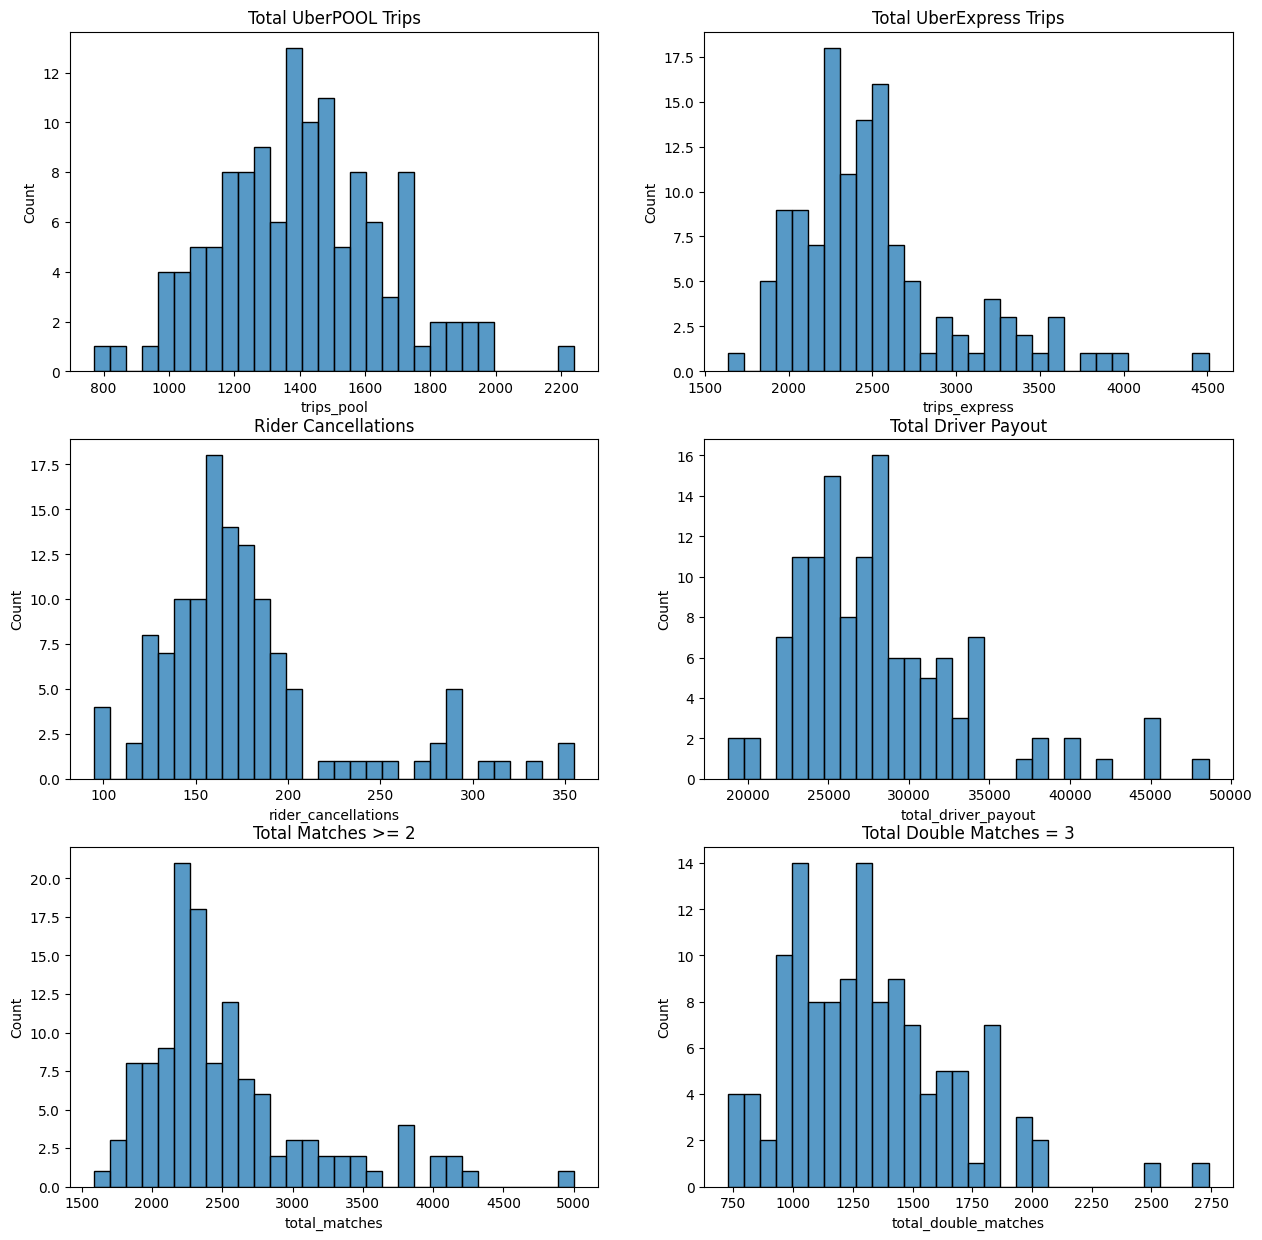

In [638]:
fig, axes = plt.subplots(3, 2, figsize=(15, 15))

sns.histplot(df_uber["trips_pool"], bins=30, kde=False, ax=axes[0,0])
axes[0,0].set_title("Total UberPOOL Trips")

sns.histplot(df_uber["trips_express"], bins=30, kde=False, ax=axes[0,1])
axes[0,1].set_title("Total UberExpress Trips")

# Row 2
sns.histplot(df_uber["rider_cancellations"], bins=30, kde=False, ax=axes[1,0])
axes[1,0].set_title("Rider Cancellations")

sns.histplot(df_uber["total_driver_payout"], bins=30, kde=False, ax=axes[1,1])
axes[1,1].set_title("Total Driver Payout")

# Row 3
sns.histplot(df_uber["total_matches"], bins=30, kde=False, ax=axes[2,0])
axes[2,0].set_title("Total Matches >= 2")

sns.histplot(df_uber["total_double_matches"], bins=30, kde=False, ax=axes[2,1])
axes[2,1].set_title("Total Double Matches = 3")

### Outliers

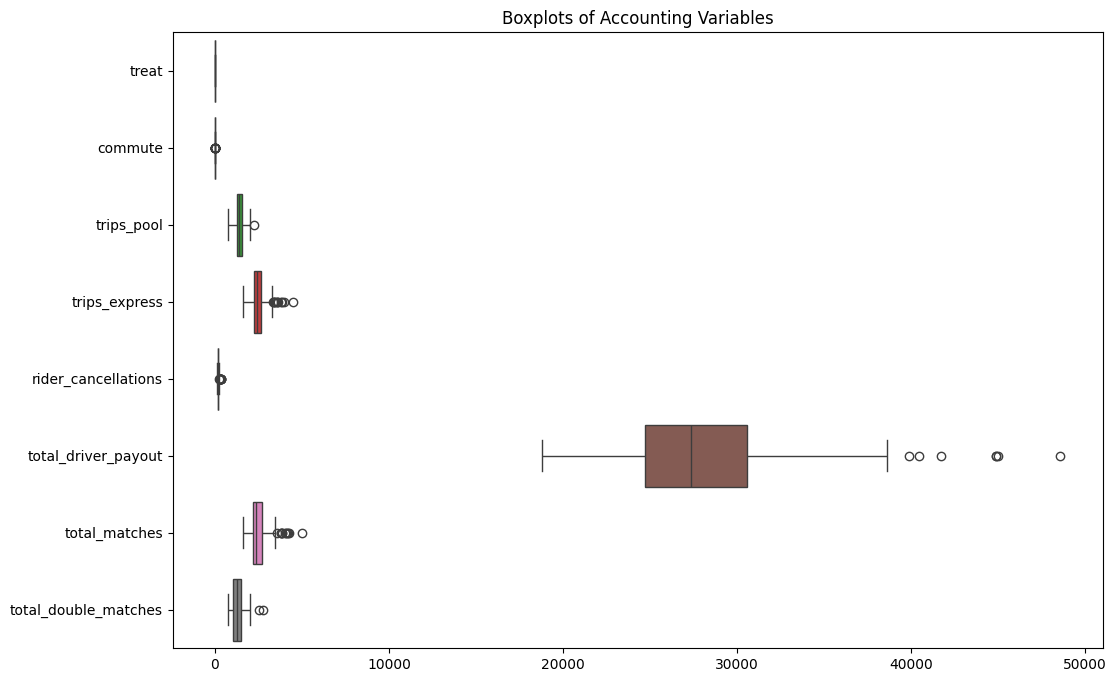

In [639]:
plt.figure(figsize=(12, 8))

sns.boxplot(data=df_uber.select_dtypes(include='number'), orient="h")

plt.title("Boxplots of Accounting Variables")
plt.show()

Although there are some outliers, these may represent real demand fluctiations in the market. Therefor, these were not removed to be able to preserve the true distribution of economic values and rider behaviour.

## Feature Engineering (Variable Construction)

To evaluate the impact of extending the matching window from 2 minutes to 5 minutes we aim to assess both customer experience and efficiency under the two treatment conditions. As seen in Table 1, by constructing new variables from the existing variables and observations, we derive interpretable metrics that capture custumer behaviour,experience and system efficiency: 

## Table 1: Engineered Metrics by Category

| Category | Variable |
|----------|----------|
| **Demand** | total_shared_trips |
|  | total_requests |
| **Matching Efficiency** | overall_match_rate |
|  | double_match_rate |
| **Customer Experience** | cancellation_rate |
| **Operational Efficiency** | occupancy_per_trip |
|  | occupied_seats_per_min |
| **Cost Efficiency** | driver_payout_per_trip |
|  | driver_cost_per_rider |
| **Product Mix** | pool_share |
|  | express_share |
| **Time-Based Variables** | hour |
|  | is_weekend |
|  | segment |
|  | wait_label |
|  | commute_label |

**Note:** Demand metrics approximate rider willingness (opt-in behavior), while cancellation rates capture realized customer experience. Matching, efficiency, and cost metrics assess how effectively the system operates under different wait-time conditions.

These key variables were constructed using the following principles:
- Each completed trip corresponds to a single rider request, allowing total trips to represent total riders.
- Matching metrics are derived from aggregates provided by Uber where total_matches resfects both 2 and 3 rider matches and total_double_matches only reflexts maximum capacity matches.
- Vehicle utilization is approximated by decomposing trips into single, pair, and triple matches in which we assume riders are frouped perfectly into shared vehicles.
- Time-based variables are extracted from the period timestamp to control for demand variation across hours, commuting periods, and weekends.
- These engineered features enable a structured comparison of treatment (5-minute wait) versus control (2-minute wait) across different demand conditions, ensuring that observed effects reflect behavioral changes as opposed to temporal imbalances.

The below table, Table 2, summarizes the engineered variables with their interpretations and their underlying assumptions:

### Table 2: Feature Engineering Summary Table

| Variable | Definition | Interpretation | Assumptions |
|----------|-----------|---------------|-------------|
| **total_shared_trips** | `trips_pool + trips_express` | Total number of completed shared trips (proxy for total riders served) | Each trip corresponds to one rider request |
| **total_requests** | `total_matches + rider_cancellations` | Proxy for total demand (matched + cancelled requests) | Unmatched demand is captured via cancellations (approximation) |
| **triple_requests** | `total_double_matches` | Number of rider-requests involved in 3-person matches | Each triple match contributes 3 rider-level matches |
| **pair_requests** | `total_matches - total_double_matches` | Number of rider-requests involved in 2-person matches | Remaining matches are pair matches |
| **single_requests** | `total_trips - total_matches` | Number of riders not matched with others (solo trips) | All non-matched trips are solo |
| **overall_match_rate** | `total_matches / total_requests` | Probability that a rider is successfully matched | total_requests is correctly approximated |
| **double_match_rate** | `total_double_matches / total_matches` | Share of matches that involve 3 riders (higher efficiency matching) | total_matches > 0; reflects intensity of matching |
| **cancellation_rate** | `rider_cancellations / total_requests` | Proxy for customer experience (higher = worse experience) | Cancellations reflect dissatisfaction or waiting friction |
| **pool_share** | `trips_pool / total_trips` | Share of UberPOOL usage | Total trips fully capture shared demand |
| **express_share** | `trips_express / total_trips` | Share of UberExpress usage | Same as above |
| **pair_trips** | `pair_requests / 2` | Estimated number of vehicles serving 2 riders | Each pair match uses 1 vehicle |
| **triple_trips** | `triple_requests / 3` | Estimated number of vehicles serving 3 riders | Each triple match uses 1 vehicle |
| **utilised_vehicles** | `single_requests + pair_trips + triple_trips` | Estimated number of vehicles used | Perfect grouping: singles (1), pairs (2), triples (3) |
| **occupancy_per_trip** | `total_trips / utilised_vehicles` | Average number of riders per vehicle (efficiency metric) | Pair = 2 riders, triple = 3 riders exactly |
| **occupied_seats_per_min** | `total_trips / 160` | Throughput: riders served per minute | Each observation covers a 160-minute period |
| **driver_payout_per_trip** | `total_driver_payout / total_trips` | Average cost per completed trip | Costs scale linearly with trips |
| **driver_cost_per_rider** | `total_driver_payout / total_matches` | Cost efficiency per matched rider | Only matched riders contribute to efficiency gains |
| **hour** | Extracted from `period_start` | Captures time-of-day variation in demand | Hour adequately represents temporal patterns |
| **is_weekend** | `dayofweek >= 5` | Differentiates weekend vs weekday demand | Weekend behavior differs structurally |
| **segment** | `"Rush/Non-Rush" + "Weekend/Weekday"` | Combines demand conditions into meaningful groups | Commute and weekend capture major demand variation |
| **wait_label** | Mapping of `treat` to readable labels | Improves interpretability in plots | No analytical impact |
| **commute_label** | Mapping of `commute` to readable labels | Improves interpretability in plots | No analytical impact |


**Note:** Some efficiency metrics rely on simplifying assumptions about rider grouping. These are used alongside directly observed metrics (e.g., match rates) to ensure robust conclusions.

### Demand Metrics

In [640]:
df_uber["total_shared_trips"] = df_uber["trips_pool"] + df_uber["trips_express"]

In [641]:
df_uber["total_requests"] = df_uber["total_shared_trips"] + df_uber["rider_cancellations"]

### Matching Efficiency Metrics

In [642]:
df_uber["overall_match_rate"] = df_uber["total_matches"] / df_uber["total_requests"]

In [643]:
df_uber["double_match_rate"] = df_uber["total_double_matches"] / df_uber["total_matches"]

### Custumer Experience Metric

In [644]:
df_uber["cancellation_rate"] = df_uber["rider_cancellations"] / df_uber["total_requests"]

### Product Mix Metrics

In [645]:
df_uber["express_share"] = df_uber["trips_express"] / df_uber["total_shared_trips"]

In [646]:
df_uber["pool_share"] = df_uber["trips_pool"] / df_uber["total_shared_trips"]

### Operational Efficiency Metrics

In [647]:
df_uber["triple_requests"] = df_uber["total_double_matches"]
df_uber["pair_requests"] = df_uber["total_matches"] - df_uber["total_double_matches"]
df_uber["single_requests"] = df_uber["total_shared_trips"] - df_uber["total_matches"]

In [648]:
df_uber["pair_trips"] = df_uber["pair_requests"] / 2
df_uber["triple_trips"] = df_uber["triple_requests"] / 3

In [649]:
df_uber["utilised_vehicles"] = (
    df_uber["single_requests"]
    + df_uber["pair_trips"]
    + df_uber["triple_trips"]
)

In [650]:
df_uber["occupancy_per_trip"] = df_uber["total_shared_trips"] / df_uber["utilised_vehicles"]

In [651]:
df_uber["occupied_seats_per_min"] = df_uber["total_shared_trips"] / 160

### Cost Efficiency Metrics

In [652]:
df_uber["driver_payout_per_trip"] = (
    df_uber["total_driver_payout"] / df_uber["total_shared_trips"]
)

In [653]:
df_uber["driver_cost_per_rider"] = df_uber["total_driver_payout"] / df_uber["total_matches"]

### Time-Based Variables

In [654]:
df_uber['hour'] = (pd.to_datetime(df_uber['period_start'])).dt.hour

In [655]:
df_uber["is_weekend"] = (df_uber["period_start"].dt.dayofweek >= 5).map({False:0,True:1}).astype("category")

In [656]:
df_uber["segment"] = (
    df_uber["commute"].map({1: "Rush", 0: "Non-Rush"}).astype(str) + " | " + #merging commute and weekend
    df_uber["is_weekend"].map({1: "Weekend", 0: "Weekday"}).astype(str)
)

In [657]:
# readable label for commute and wait
df_uber["commute_label"] = df_uber["commute"].map({0: "Non-Rush Hour", 1: "Rush Hour"})

# readable label for treatment condition
df_uber["wait_label"] = df_uber["treat"].map({0: "2-min (control)", 1: "5-min (treatment)"})

In [658]:
df_uber.head(10)

,period_start,wait_time,treat,commute,trips_pool,trips_express,rider_cancellations,total_driver_payout,total_matches,total_double_matches,...,utilised_vehicles,occupancy_per_trip,occupied_seats_per_min,driver_payout_per_trip,driver_cost_per_rider,hour,is_weekend,segment,commute_label,wait_label
0,2018-02-19 07:00:00,2,0,1,1415,3245,256,34458.411634,3372,1476,...,2728.000000,1.708211,29.12500,7.394509,10.218983,7,0,Rush | Weekday,Rush Hour,2-min (control)
1,2018-02-19 09:40:00,5,1,0,1461,2363,203,29764.349821,2288,1275,...,2467.500000,1.549747,23.90000,7.783564,13.008894,9,0,Non-Rush | Weekday,Non-Rush Hour,5-min (treatment)
2,2018-02-19 12:20:00,2,0,0,1362,2184,118,27437.367363,2283,962,...,2244.166667,1.580097,22.16250,7.737554,12.018120,12,0,Non-Rush | Weekday,Non-Rush Hour,2-min (control)
3,2018-02-19 15:00:00,5,1,1,1984,3584,355,44995.452993,4035,2021,...,3213.666667,1.732600,34.80000,8.081080,11.151289,15,0,Rush | Weekday,Rush Hour,5-min (treatment)
4,2018-02-19 17:40:00,2,0,0,1371,2580,181,27583.955295,2200,979,...,2687.833333,1.469957,24.69375,6.981512,12.538161,17,0,Non-Rush | Weekday,Non-Rush Hour,2-min (control)
5,2018-02-19 20:20:00,5,1,0,1401,2022,135,23888.110848,2066,1062,...,2213.000000,1.546769,21.39375,6.978706,11.562493,20,0,Non-Rush | Weekday,Non-Rush Hour,5-min (treatment)
6,2018-02-19 23:00:00,2,0,0,1216,2543,103,29642.905668,2600,1406,...,2224.666667,1.689691,23.49375,7.885849,11.401118,23,0,Non-Rush | Weekday,Non-Rush Hour,2-min (control)
7,2018-02-20 01:40:00,5,1,0,1691,2018,150,25794.869920,1918,1281,...,2536.500000,1.462251,23.18125,6.954670,13.448837,1,0,Non-Rush | Weekday,Non-Rush Hour,5-min (treatment)
8,2018-02-20 04:20:00,2,0,0,1248,2481,131,23238.946288,2623,1059,...,2241.000000,1.663989,23.30625,6.231951,8.859682,4,0,Non-Rush | Weekday,Non-Rush Hour,2-min (control)
9,2018-02-20 07:00:00,5,1,1,1815,2539,284,34047.473898,2624,1565,...,2781.166667,1.565530,27.21250,7.819815,12.975409,7,0,Rush | Weekday,Rush Hour,5-min (treatment)


In [659]:
df_uber.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 126 entries, 0 to 125
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   period_start            126 non-null    datetime64[ns]
 1   wait_time               126 non-null    category      
 2   treat                   126 non-null    int64         
 3   commute                 126 non-null    int64         
 4   trips_pool              126 non-null    int64         
 5   trips_express           126 non-null    int64         
 6   rider_cancellations     126 non-null    int64         
 7   total_driver_payout     126 non-null    float64       
 8   total_matches           126 non-null    int64         
 9   total_double_matches    126 non-null    int64         
 10  total_shared_trips      126 non-null    int64         
 11  total_requests          126 non-null    int64         
 12  overall_match_rate      126 non-null    float64   

# Explanatory Analysis

In order to reveal the initial trends and differences between treatment and control groups, an exploratory data analysis (EDA) was conducted. This analysis helped us understan the key patterns in demand, matching efficiency, and rider behavior across different conditions.

## Demand vs Customer Experience

In [660]:
means_total = df_uber.groupby("wait_time", observed=True)["total_requests"].mean()
means_shared = df_uber.groupby("wait_time", observed=True)["total_shared_trips"].mean()
means_cancel = df_uber.groupby("wait_time", observed=True)["cancellation_rate"].mean()

# Compute % changes
pct_total_change = (means_total.loc[5] - means_total.loc[2]) / means_total.loc[2] * 100
pct_shared_change = (means_shared.loc[5] - means_shared.loc[2]) / means_shared.loc[2] * 100
pct_cancel_change = (means_cancel.loc[5] - means_cancel.loc[2]) / means_cancel.loc[2] * 100

# Combine into one table
df_total_cancel = pd.DataFrame({
    "Metric": ["total_requests","total_shared_trips", "cancellation_rate"],
    "Mean (2 min)": [means_total.loc[2],means_shared.loc[2], means_cancel.loc[2]],
    "Mean (5 min)": [means_total.loc[5],means_shared.loc[5], means_cancel.loc[5]],
    "% Change": [pct_total_change,pct_shared_change, pct_cancel_change]
})

df_total_cancel

,Metric,Mean (2 min),Mean (5 min),% Change
0,total_requests,4132.333333,4070.206349,-1.503436
1,total_shared_trips,3966.984127,3880.079365,-2.190701
2,cancellation_rate,0.039549,0.046202,16.821374


The results show a modest decline in total requests under the 5-minute policy, indicating a slight reduction in rider demand. However, the decline in total shared trips is larger, suggesting that fewer rides are ultimately completed. This gap is explained by a substantial increase in the cancellation rate, indicating that the primary impact of longer wait times occurs after riders have already entered the system. In other words, the policy leads to higher abandonment rather than simply lower initial demand.

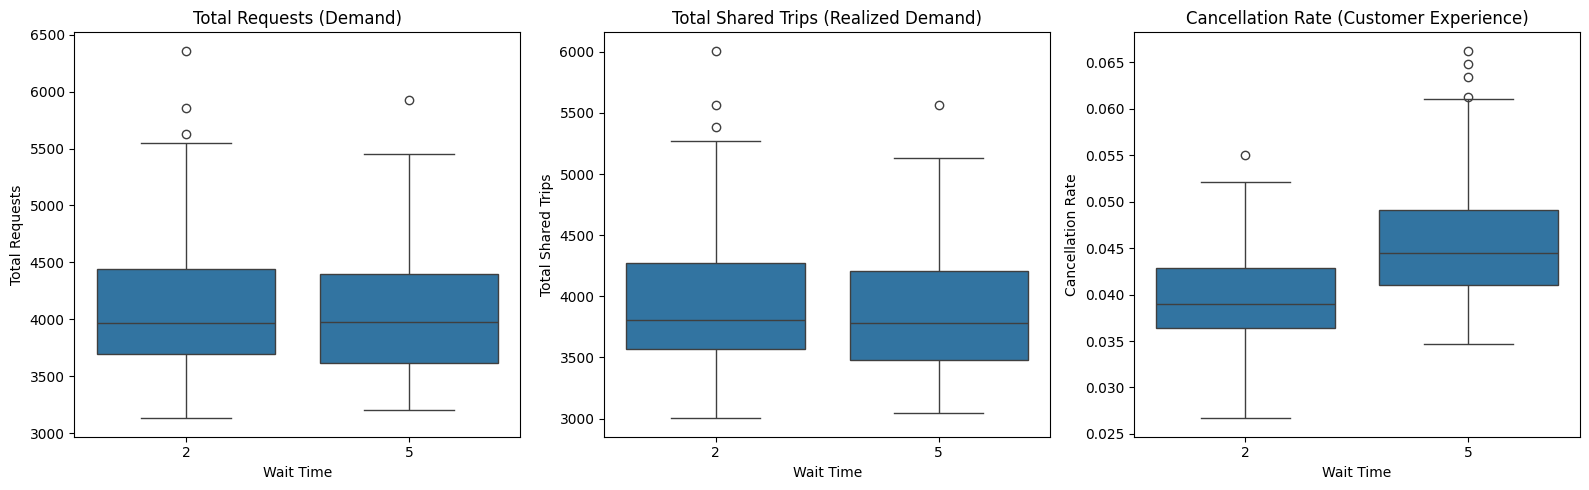

In [661]:
fig, axes = plt.subplots(1, 3, figsize=(16,5))

# 📊 Total Requests
sns.boxplot(
    data=df_uber,
    x="wait_time",
    y="total_requests",
    ax=axes[0]
)
axes[0].set_title("Total Requests (Demand)")
axes[0].set_xlabel("Wait Time")
axes[0].set_ylabel("Total Requests")

sns.boxplot(
    data=df_uber,
    x="wait_time",
    y="total_shared_trips",
    ax=axes[1]
)
axes[1].set_title("Total Shared Trips (Realized Demand)")
axes[1].set_xlabel("Wait Time")
axes[1].set_ylabel("Total Shared Trips")

# 📊 Cancellation Rate
sns.boxplot(
    data=df_uber,
    x="wait_time",
    y="cancellation_rate",
    ax=axes[2]
)
axes[2].set_title("Cancellation Rate (Customer Experience)")
axes[2].set_xlabel("Wait Time")
axes[2].set_ylabel("Cancellation Rate")

plt.tight_layout()
plt.show()

The boxplots reveal that increasing wait time from 2 to 5 minutes leads to a consistent downward shift in total requests, even larger downward shift in total shared trips and an upward shift in cancellation rates across the entire distribution. This indicates that the negative impact on rider demand and customer experience is not driven by outliers but is a systematic effect, reinforcing the concern that longer wait times reduce platform attractiveness.

In [662]:
df_demand_cancel_plot = df_uber[[ #getting a coppy
    "hour", "segment", "treat", "wait_label",
    "cancellation_rate", "total_requests","total_shared_trips"
]].copy()

df_demand_cancel_melted = df_demand_cancel_plot.melt( #converting thhe format of the data frame
    id_vars=["hour", "segment", "treat","wait_label"],
    value_vars=["cancellation_rate", "total_requests","total_shared_trips"],
    var_name="metric",
    value_name="value"
)

df_demand_cancel_melted = df_demand_cancel_melted.sort_values( #sorting melted data
    ["segment", "treat", "metric", "hour","wait_label"]
)

df_demand_cancel_melted["metric"] = df_demand_cancel_melted["metric"].replace({ #renaming metrics
    "cancellation_rate": "Rider Cancelation Rate",
    "total_requests": "Total Demand",
    "total_shared_trips": "Total Realized Demand"
})

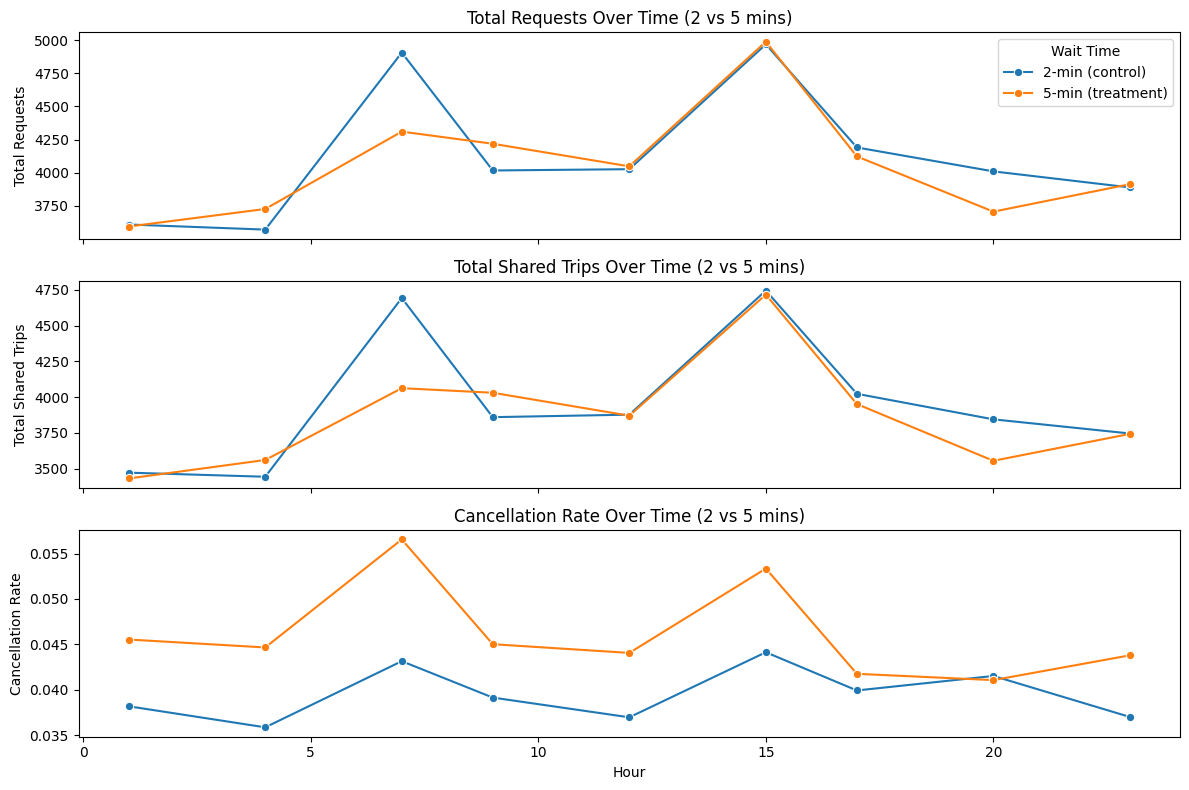

In [663]:
fig, axes = plt.subplots(3, 1, figsize=(12,8), sharex=True)

# 🔵 total requests
sns.lineplot(
    data=df_demand_cancel_melted[df_demand_cancel_melted["metric"] == "Total Demand"],
    x="hour",
    y="value",
    hue="wait_label",
    errorbar=None,
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Total Requests Over Time (2 vs 5 mins)")
axes[0].set_ylabel("Total Requests")
axes[0].set_xlabel("")

#total shared trips
sns.lineplot(
    data=df_demand_cancel_melted[df_demand_cancel_melted["metric"] == "Total Realized Demand"],
    x="hour",
    y="value",
    hue="wait_label",
    errorbar=None,
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Total Shared Trips Over Time (2 vs 5 mins)")
axes[1].set_ylabel("Total Shared Trips")
axes[1].set_xlabel("")

#cancelation rates
sns.lineplot(
    data=df_demand_cancel_melted[df_demand_cancel_melted["metric"] == "Rider Cancelation Rate"],
    x="hour",
    y="value",
    hue="wait_label",
    errorbar=None,
    marker="o",
    ax=axes[2]
)

axes[2].set_title("Cancellation Rate Over Time (2 vs 5 mins)")
axes[2].set_ylabel("Cancellation Rate")
axes[2].set_xlabel("Hour")


# legends only 1
axes[2].legend_.remove()
axes[1].legend_.remove()
axes[0].legend(title="Wait Time")

plt.tight_layout()
plt.show()

The time-series analysis shows that increasing wait time from 2 to 5 minutes leads to consistently lower overall demand and higher cancellation rates across all hours of the day. While demand naturally peaks during certain periods, the treatment effect remains negative throughout, with particularly noticeable reductions during high-demand hours. Similarly, cancellation rates are systematically higher under the longer wait policy at all times, indicating that the deterioration in customer experience is both persistent and widespread.

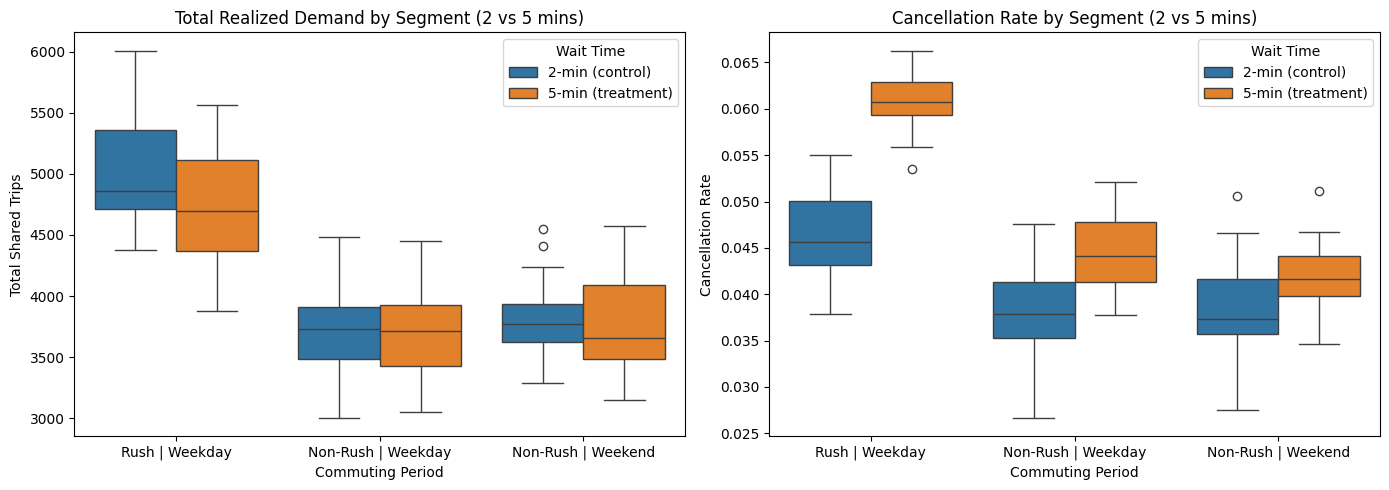

In [664]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# total shared trips
sns.boxplot(
    data=df_uber,
    x="segment",
    y="total_shared_trips",
    hue="wait_label",
    ax=axes[0]
)
axes[0].set_title("Total Realized Demand by Segment (2 vs 5 mins)")
axes[0].set_xlabel("Commuting Period")
axes[0].set_ylabel("Total Shared Trips")


# 📊 Cancellation plot
sns.boxplot(
    data=df_uber,
    x="segment",
    y="cancellation_rate",
    hue="wait_label",
    ax=axes[1]
)
axes[1].set_title("Cancellation Rate by Segment (2 vs 5 mins)")
axes[1].set_xlabel("Commuting Period")
axes[1].set_ylabel("Cancellation Rate")

#legends only 1
axes[0].legend(title="Wait Time")
axes[1].legend(title="Wait Time")

plt.tight_layout()
plt.show()

Across all segments, longer wait times primarily reduce demand, indicating lower rider willingness to engage with the platform. This effect is more pronounced on rush weekdays, suggesting that weekday riders are more sensitive to wait times when travel needs are less urgent. In contrast, cancellation rates increase significantly, indicating that riders are more likely to abandon requests due to heightened time sensitivity. This effect is particularly strong on weekdays, when commuting constraints are tighter, whereas weekends exhibit more moderate increases in cancellations. Overall, this highlights that the negative effects of longer wait times vary not only by demand intensity but also by the nature of travel, differing between weekday and weekend usage patterns.

While the boxplots provide a summary comparison of treatment effects across segments, the time-series plots reveal how these effects evolve over time, uncovering important temporal patterns and differences in rider behavior across hours.

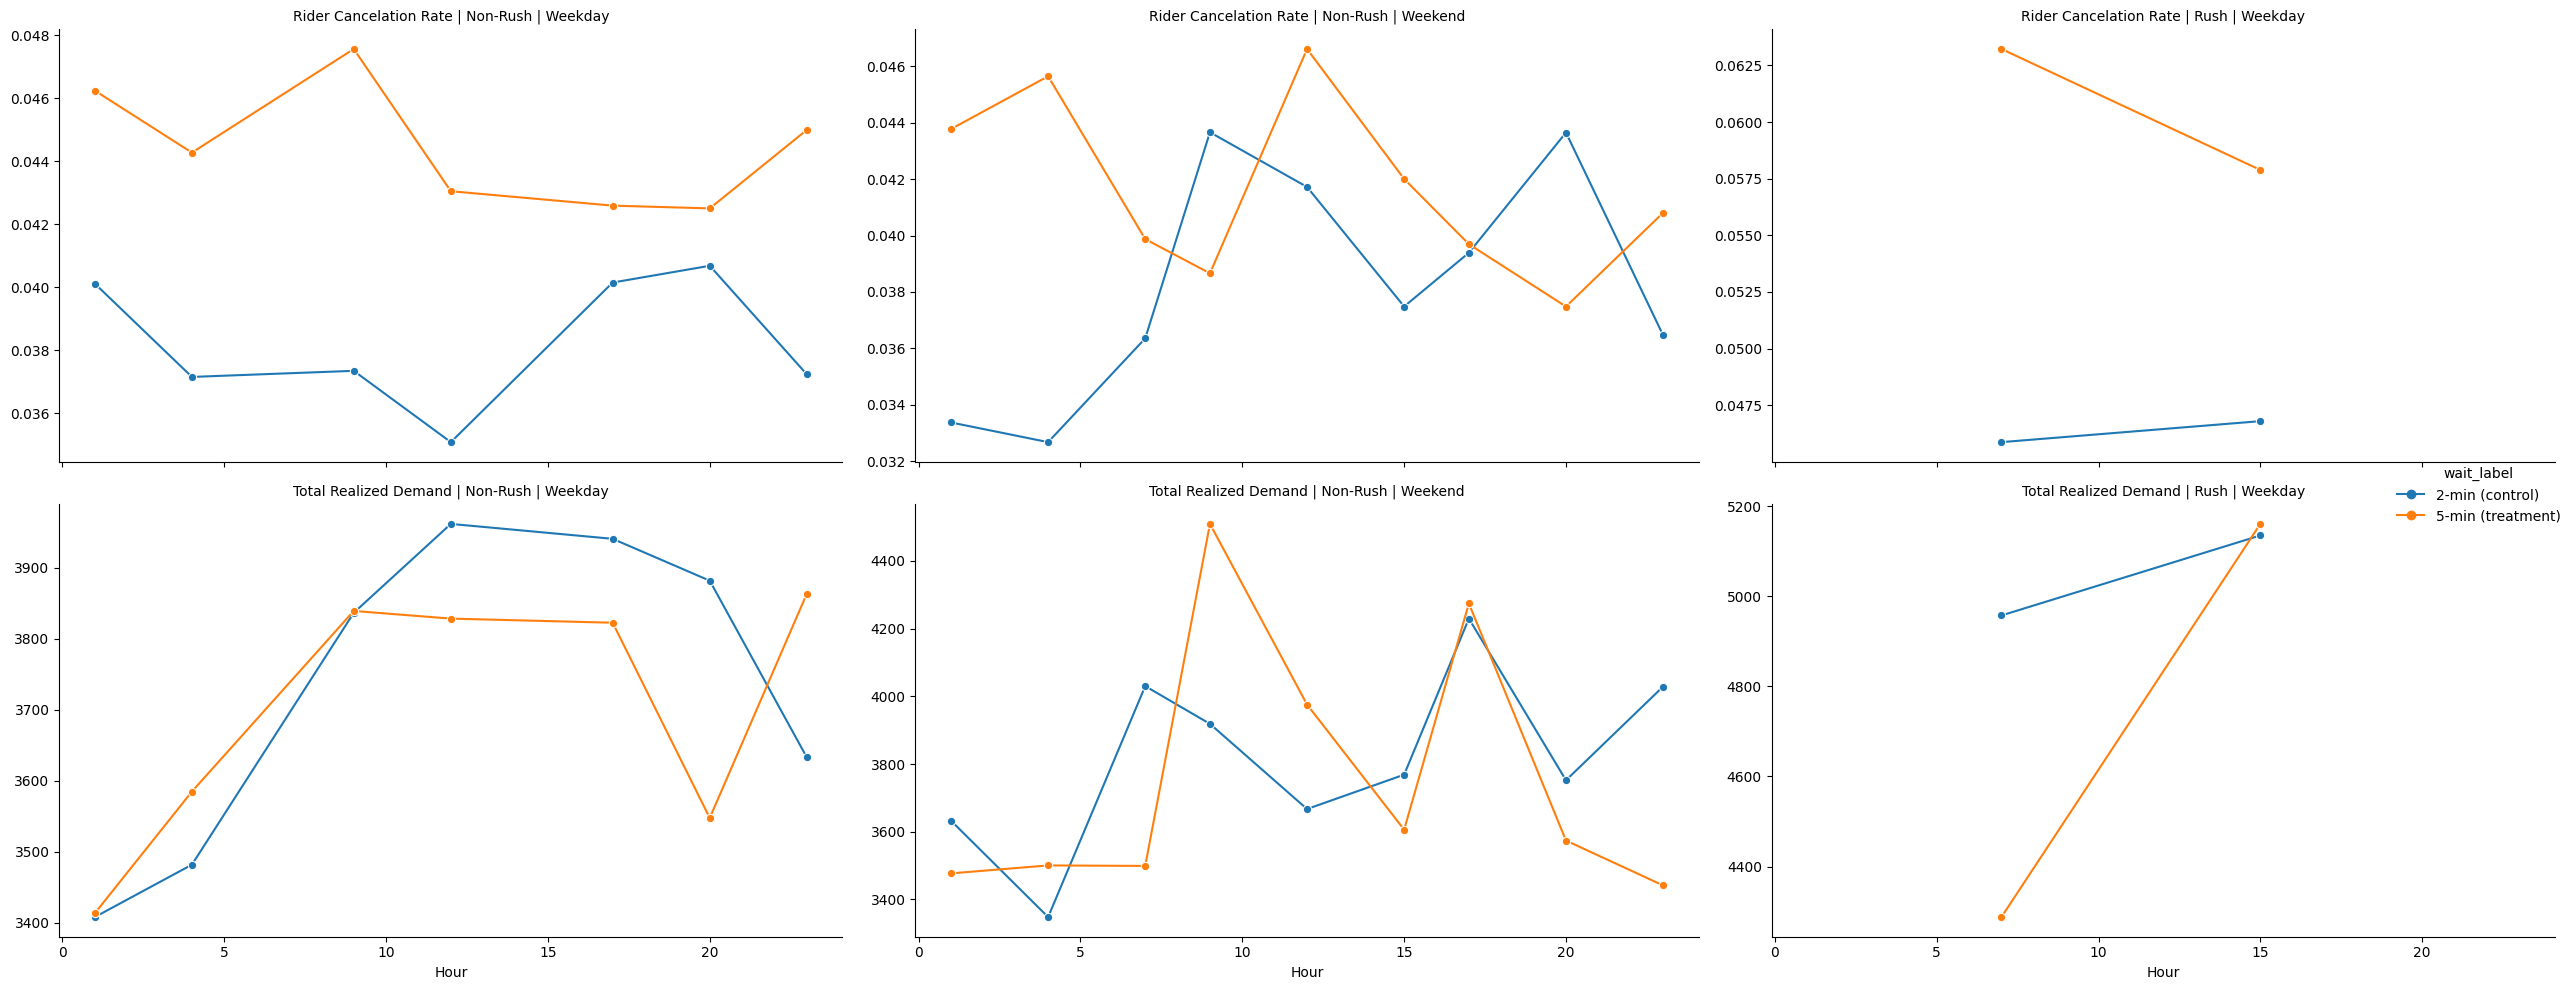

In [665]:
g = sns.relplot(
    data=df_demand_cancel_melted[
    df_demand_cancel_melted["metric"].isin([ #use only these 2 metrics from melted
        "Total Realized Demand",
        "Rider Cancelation Rate"
    ])
],
    x="hour",
    y="value",
    hue="wait_label",
    col="segment",          # columns = segments
    row="metric",           # rows = cancellation vs total shared trips
    kind="line",
    height=5,
    aspect=1.6,
    errorbar=None,
    marker="o",
    facet_kws={"sharey": False} #scale axis dynamicly
)

# titles
g.set_titles("{row_name} | {col_name}")

# labels
g.set_axis_labels("Hour", "")


plt.tight_layout()
plt.show()

The segmented analysis reveals that the impact of longer wait times varies significantly across market conditions. During non-rush weekdays, longer wait times primarily reduce demand, indicating that riders are less willing to engage with the platform. On weekends, both demand and cancellation responses are more variable, suggesting lower time sensitivity and more flexible travel behavior. In contrast, during weekday rush hours, demand remains relatively stable under longer wait times, but cancellation rates increase sharply, indicating that riders continue to request rides due to necessity but are more likely to abandon them when faced with delays. This highlights that the costs of longer wait times shift from reduced demand in low-urgency periods to deteriorating customer experience in high-urgency periods.

### POOL vs Express

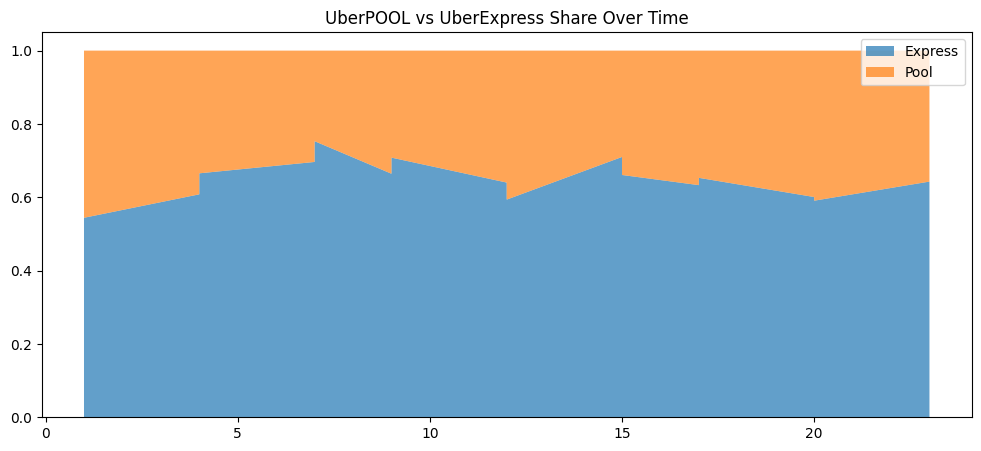

In [666]:
df_plot = df_uber.sort_values(["hour"]) #sorting by hour

plt.figure(figsize=(12,5))

plt.stackplot(
    df_plot["hour"],
    df_plot["express_share"],
    df_plot["pool_share"],
    labels=["Express", "Pool"],
    alpha=0.7
)

plt.legend(loc="upper right") #fix legend up right
plt.title("UberPOOL vs UberExpress Share Over Time")
plt.show()

The distribution of trips between UberPOOL and UberExpress remains relatively stable over time, with UberExpress consistently accounting for the majority of rides. This suggests that rider preferences between service types are broadly stable throughout the day, and that any impact of longer wait times is unlikely to be driven by large shifts in product choice. Instead, the effects of the treatment are more likely to operate through changes in demand, cancellations, and matching efficiency.

In [667]:
means_types = df_uber.groupby("wait_time", observed=True)[["express_share", "pool_share"]].mean() #getting means for both express and pool share


pct_change_types = (means_types.loc[5] - means_types.loc[2]) / means_types.loc[2] * 100 #percentage mean change from 2 to 5

# Combining into one table
df_types = pd.DataFrame({
    "Metric": ["express_share", "pool_share"],
    "Mean (2 min)": [means_types.loc[2, "express_share"], means_types.loc[2, "pool_share"]],
    "Mean (5 min)": [means_types.loc[5, "express_share"], means_types.loc[5, "pool_share"]],
    "% Change": [pct_change_types["express_share"], pct_change_types["pool_share"]]
})

df_types

,Metric,Mean (2 min),Mean (5 min),% Change
0,express_share,0.655964,0.621877,-5.196453
1,pool_share,0.344036,0.378123,9.907942


The results indicate a clear substitution effect, with longer wait times reducing the share of UberExpress trips and increasing the share of UberPOOL trips. This reflects a system-level network effect, whereby longer wait times expand the pool of available riders at any given moment, improving matching opportunities and enabling more efficient grouping into shared rides. As a result, riders become more likely to accept pooled trips, reducing reliance on Express options. However, when considered alongside the observed increase in cancellations and decline in demand, this shift appears to occur among a smaller set of remaining riders, highlighting the trade-off between improved matching efficiency and reduced customer engagement.

In [668]:
df_uber = df_uber.sort_values(["segment", "wait_time", "hour"]) #sorting

df_ride_plot = df_uber.groupby(["wait_label"], observed=True)[["express_share", "pool_share"]].mean().reset_index() #grouping by control-treatment

df_ride_plot_melted = df_ride_plot.melt( #converting data format
    id_vars=["wait_label"],
    value_vars=["express_share", "pool_share"],
    var_name="ride_type",
    value_name="share"
)

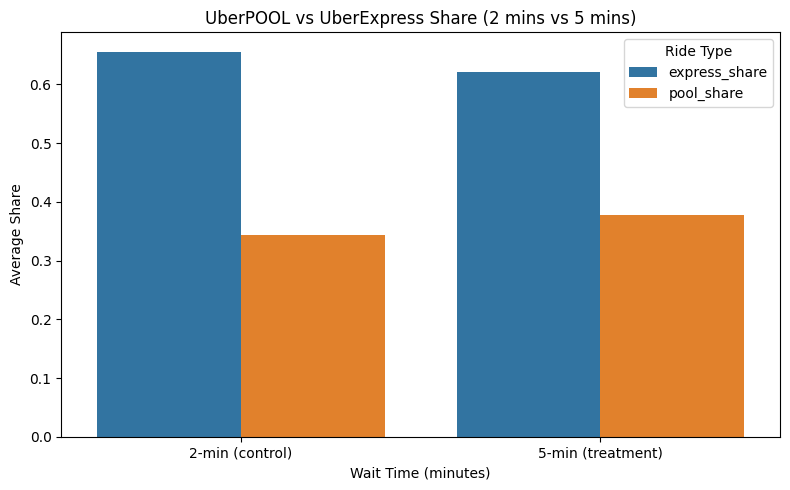

In [669]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df_ride_plot_melted,
    x="wait_label",
    y="share",
    hue="ride_type"
)

plt.title("UberPOOL vs UberExpress Share (2 mins vs 5 mins)")
plt.xlabel("Wait Time (minutes)")
plt.ylabel("Average Share")

plt.legend(title="Ride Type")
plt.tight_layout()
plt.show()

This plot further supports the presence of a substitution effect, reinforcing the earlier finding that longer wait times shift riders from UberExpress toward UberPOOL. By presenting the average shares directly, it provides a clear and intuitive confirmation of the system-level network effect, whereby increased wait times improve matching opportunities and promote pooled rides.

In [670]:
df_pool_express_plot = df_uber[[ #getting a copy
    "hour", "segment", "treat",
    "pool_share", "express_share","wait_label"
]].copy()

df_pool_express_melted = df_pool_express_plot.melt( #changing the format
    id_vars=["hour", "segment", "treat","wait_label"],
    value_vars=["pool_share", "express_share"],
    var_name="metric",
    value_name="value"
)

df_pool_express_melted = df_pool_express_melted.sort_values( #sorting 
    ["segment", "treat", "metric", "hour","wait_label"]
)

df_pool_express_melted["metric"] = df_pool_express_melted["metric"].replace({ #renaming metrics
    "pool_share": "UberPOOL Share",
    "express_share": "UberExpress Share"
})

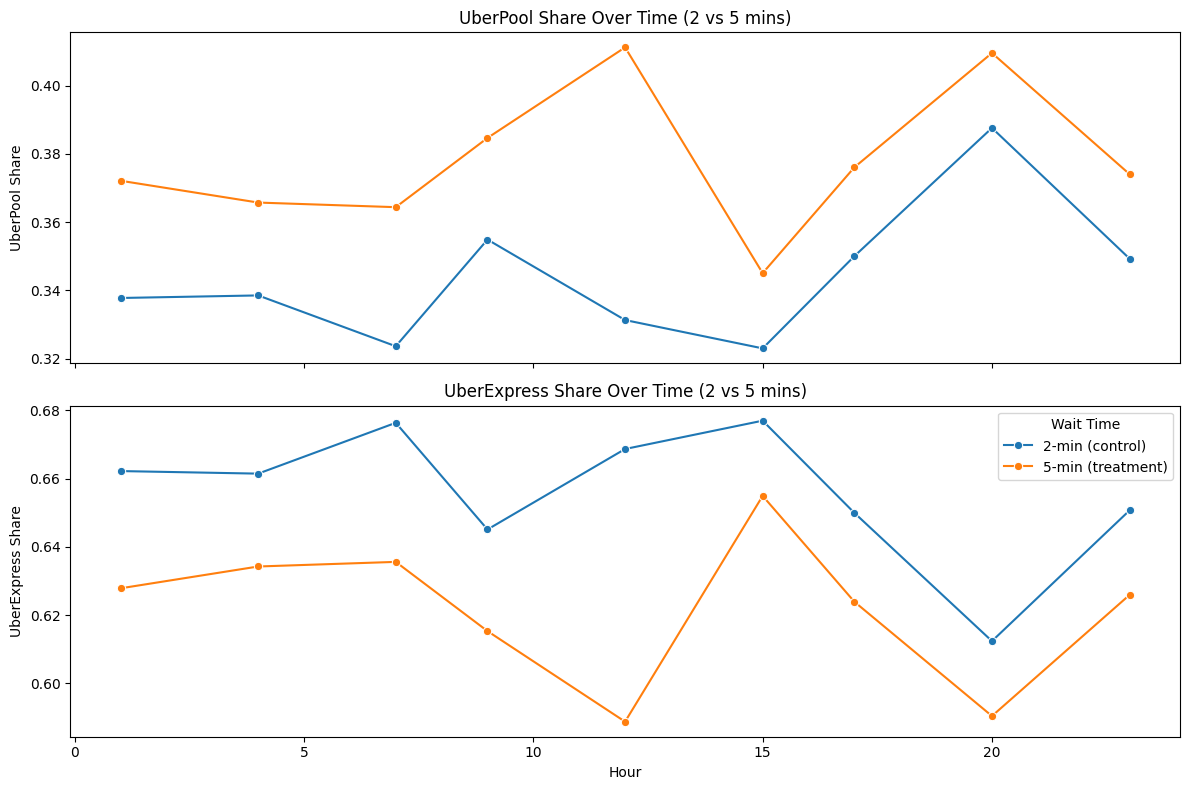

In [671]:
fig, axes = plt.subplots(2, 1, figsize=(12,8), sharex=True)

# Uberpool
sns.lineplot(
    data=df_pool_express_melted[df_pool_express_melted["metric"] == "UberPOOL Share"],
    x="hour",
    y="value",
    hue="wait_label",
    errorbar=None,
    marker="o",
    ax=axes[0]
)

axes[0].set_title("UberPool Share Over Time (2 vs 5 mins)")
axes[0].set_ylabel("UberPool Share")
axes[0].set_xlabel("")

# uberexpress
sns.lineplot(
    data=df_pool_express_melted[df_pool_express_melted["metric"] == "UberExpress Share"],
    x="hour",
    y="value",
    hue="wait_label",
    errorbar=None,
    marker="o",
    ax=axes[1]
)

axes[1].set_title("UberExpress Share Over Time (2 vs 5 mins)")
axes[1].set_ylabel("UberExpress Share")
axes[1].set_xlabel("Hour")


# legends only 1
axes[0].legend_.remove()
axes[1].legend(title="Wait Time")

plt.tight_layout()
plt.show()

The time-series analysis of product shares shows that the increase in UberPOOL usage and corresponding decrease in UberExpress usage under the longer wait-time policy is consistent across all hours of the day. This indicates that the substitution effect is not driven by specific time periods but reflects a structural shift in matching dynamics. The persistence of this pattern supports the presence of a system-level network effect, whereby increased wait times continuously improve matching opportunities and promote pooled rides.

In [672]:
means_type_commute = df_uber.groupby(["wait_time", "segment"], observed=True)[["express_share", "pool_share"]].mean() #means

pct_change_type_commute = (
    (means_type_commute.loc[5] - means_type_commute.loc[2]) / means_type_commute.loc[2] #percentage change
) * 100

pct_change_type_commute

,express_share,pool_share
segment,,
Non-Rush | Weekday,-4.602421,8.047177
Non-Rush | Weekend,-7.170690,14.627750
Rush | Weekday,-3.675250,8.499678


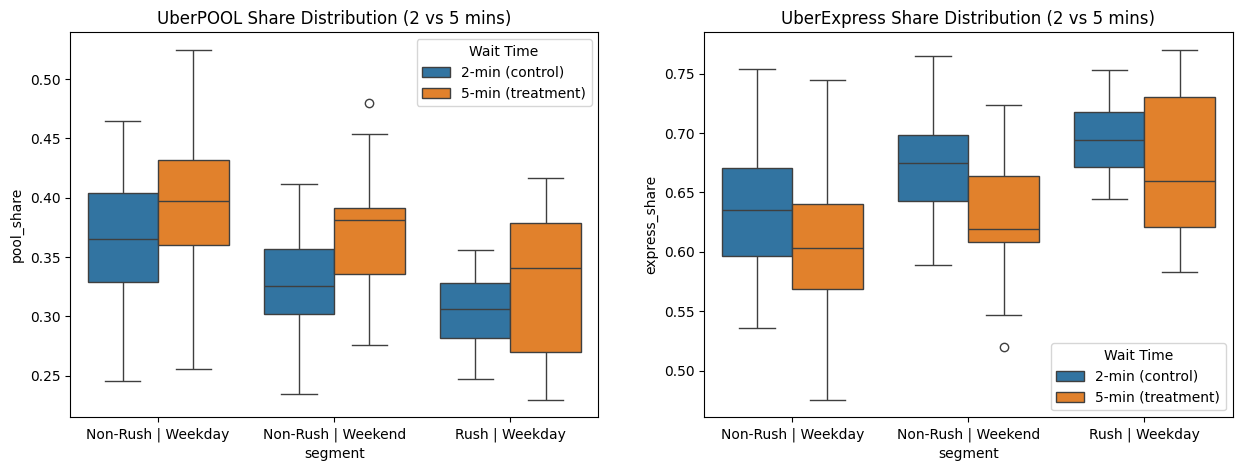

In [673]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

#uberpool
sns.boxplot(
    data=df_uber,
    x="segment",
    y="pool_share",
    hue="wait_label",
    ax=axes[0]
)
axes[0].set_title("UberPOOL Share Distribution (2 vs 5 mins)")
axes[0].legend(title="Wait Time")

#uberexpress
sns.boxplot(
    data=df_uber,
    x="segment",
    y="express_share",
    hue="wait_label",
    ax=axes[1]
)
axes[1].set_title("UberExpress Share Distribution (2 vs 5 mins)")
axes[1].legend(title="Wait Time")



The substitution effect toward UberPOOL is present across all segments, confirming the existence of a system-level network effect. However, its magnitude varies significantly by context. The largest increase in pooling occurs during non-rush weekends, where riders are more flexible and willing to accept shared rides, while the smallest shift is observed during weekday rush hours, when time sensitivity is highest. This suggests that although longer wait times improve matching opportunities across the system, the extent to which riders respond by switching to pooled rides depends on their urgency and willingness to trade off time for efficiency.

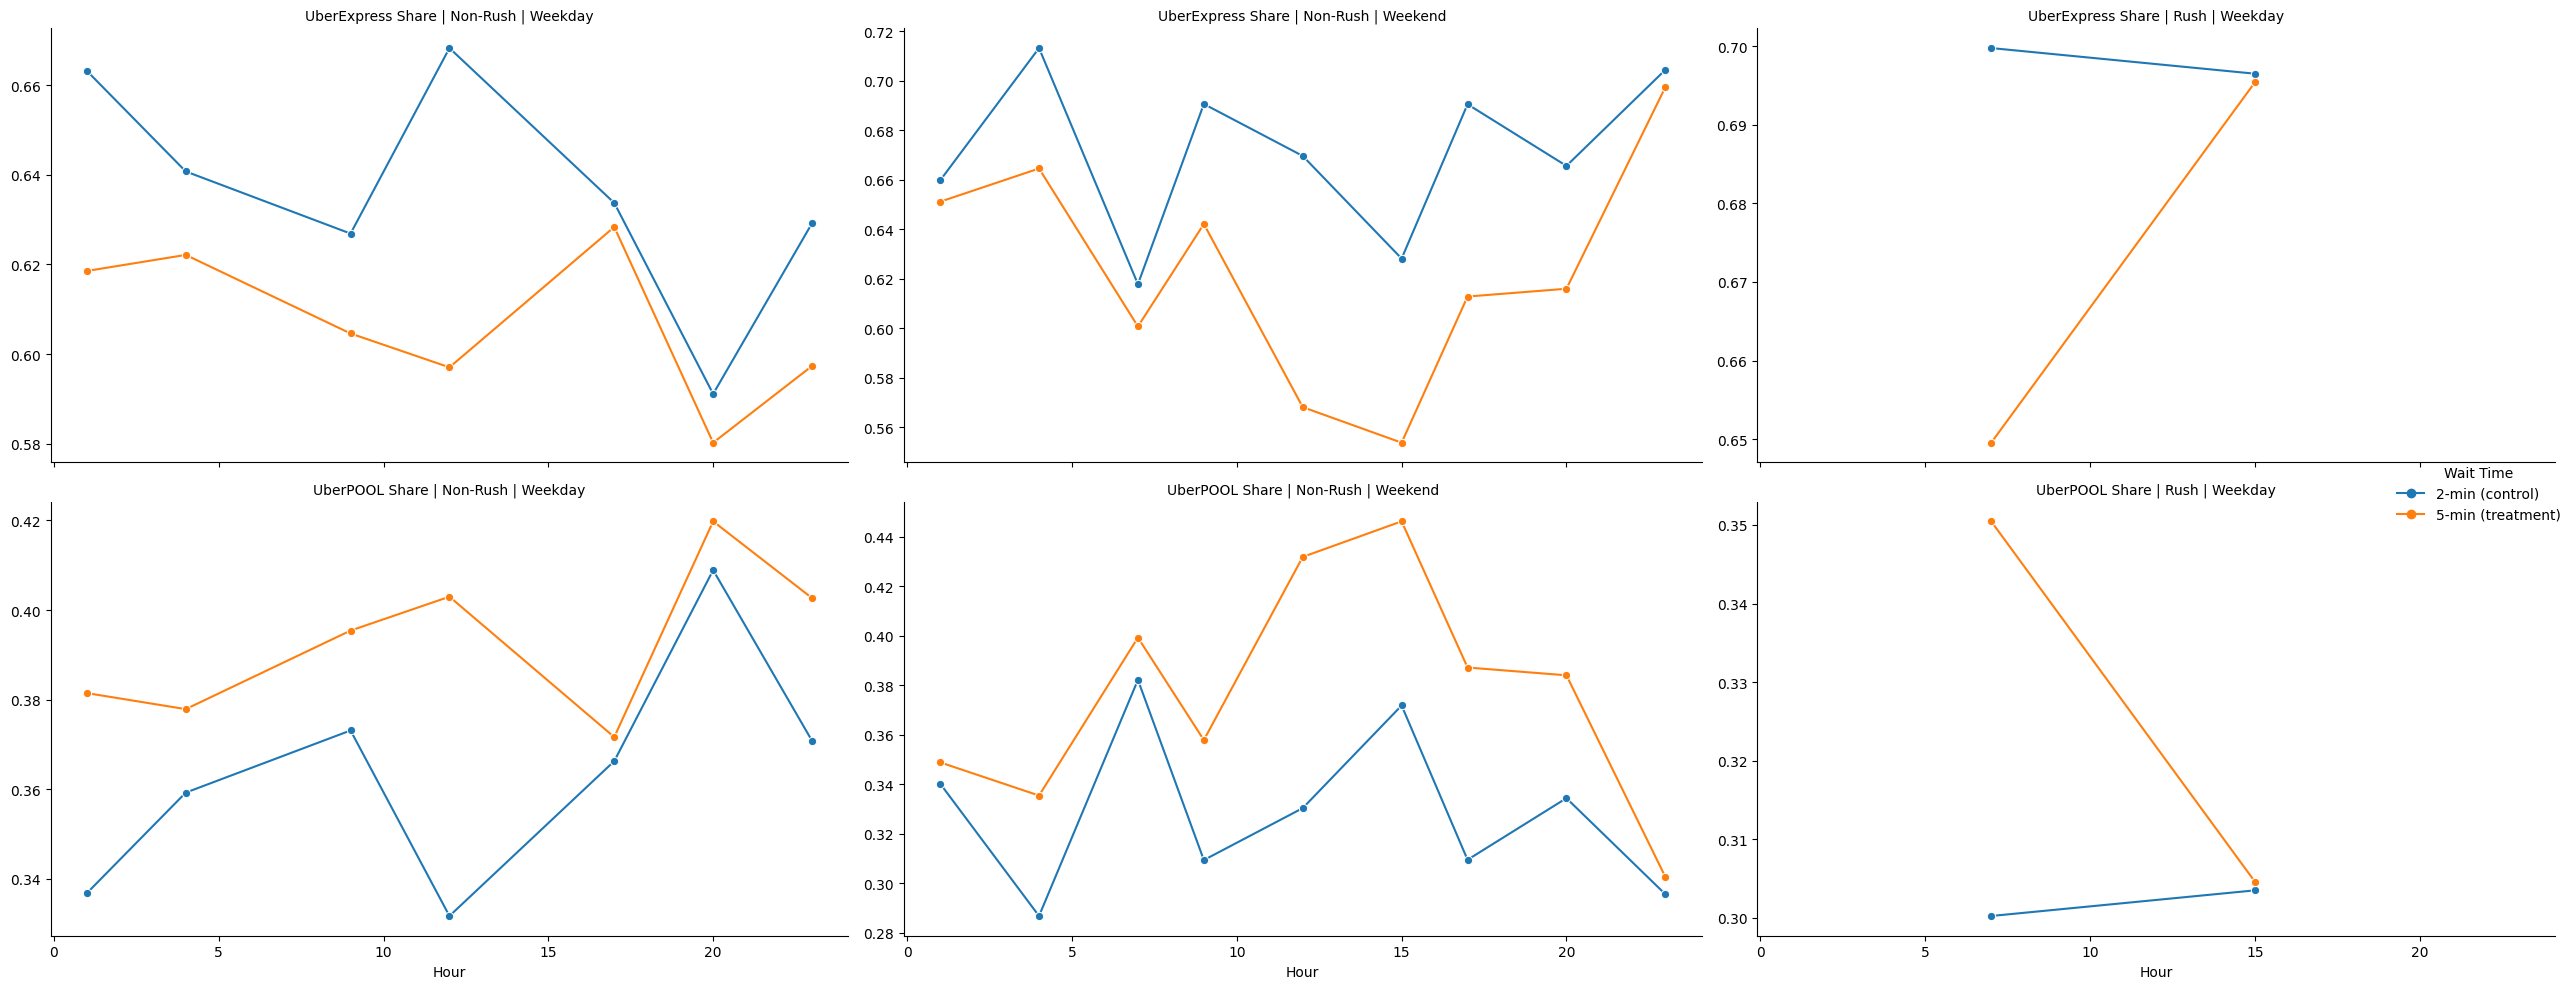

In [674]:
g = sns.relplot(
    data=df_pool_express_melted,
    x="hour",
    y="value",
    hue="wait_label",
    col="segment",          # columns = segments
    row="metric",           # rows = cancellation vs demand
    kind="line",
    height=5,
    aspect=1.6,
    errorbar=None,
    marker="o",
    facet_kws={"sharey": False}
)

# titles
g.set_titles("{row_name} | {col_name}")

# labels
g.set_axis_labels("Hour", "")
g._legend.set_title("Wait Time")

plt.tight_layout()
plt.show()

Interestingly, the difference between control and treatment narrows during rush hours, suggesting that riders are less responsive to changes in wait time during time sensitive periods. Rather than adjusting their ride choices, these riders are more likely to maintain their preferences or cancel, limiting the shift toward pooling and reducing the effectiveness of the longer wait-time policy during peak periods.

## Efficiency (Matching Efficiency vs Operational Efficiency)

In [675]:
# Means
means_overall = df_uber.groupby("wait_time", observed=True)["overall_match_rate"].mean()
means_double = df_uber.groupby("wait_time", observed=True)["double_match_rate"].mean()
means_occ_trip = df_uber.groupby("wait_time", observed=True)["occupancy_per_trip"].mean()
means_occ_min = df_uber.groupby("wait_time", observed=True)["occupied_seats_per_min"].mean()

# % changes
pct_overall_change = (means_overall.loc[5] - means_overall.loc[2]) / means_overall.loc[2] * 100
pct_double_change = (means_double.loc[5] - means_double.loc[2]) / means_double.loc[2] * 100
pct_occtrip_change = (means_occ_trip.loc[5] - means_occ_trip.loc[2]) / means_occ_trip.loc[2] * 100
pct_occmin_change = (means_occ_min.loc[5] - means_occ_min.loc[2]) / means_occ_min.loc[2] * 100

# Combining everything in a dataframe
df_efficiency = pd.DataFrame({
    "Metric": [
        "overall match rate",
        "double match rate",
        "occupancy per trip",
        "occupancy per min"
    ],
    "Mean (2 min)": [
        means_overall.loc[2],
        means_double.loc[2],
        means_occ_trip.loc[2],
        means_occ_min.loc[2]
    ],
    "Mean (5 min)": [
        means_overall.loc[5],
        means_double.loc[5],
        means_occ_trip.loc[5],
        means_occ_min.loc[5]
    ],
    "% Change": [
        pct_overall_change,
        pct_double_change,
        pct_occtrip_change,
        pct_occmin_change
    ]
})

df_efficiency.round(3)

,Metric,Mean (2 min),Mean (5 min),% Change
0,overall match rate,0.633,0.595,-5.980
1,double match rate,0.490,0.565,15.201
2,occupancy per trip,1.629,1.596,-2.032
3,occupancy per min,24.794,24.250,-2.191


The results show that increasing wait time leads to a decline in the overall match rate, indicating that fewer riders are successfully matched into shared trips. At the same time, the double match rate increases substantially, suggesting that when matches do occur, they are more likely to involve three riders and thus be more efficient. This reflects a shift in the matching strategy toward forming higher-quality, full-capacity matches rather than maximizing the number of matches. However, this comes at the cost of reduced matching frequency, likely driven by increased cancellations and rider drop-off. Consequently, despite improvements in match quality, both occupancy per trip and occupancy per minute decline, indicating that overall system efficiency deteriorates.

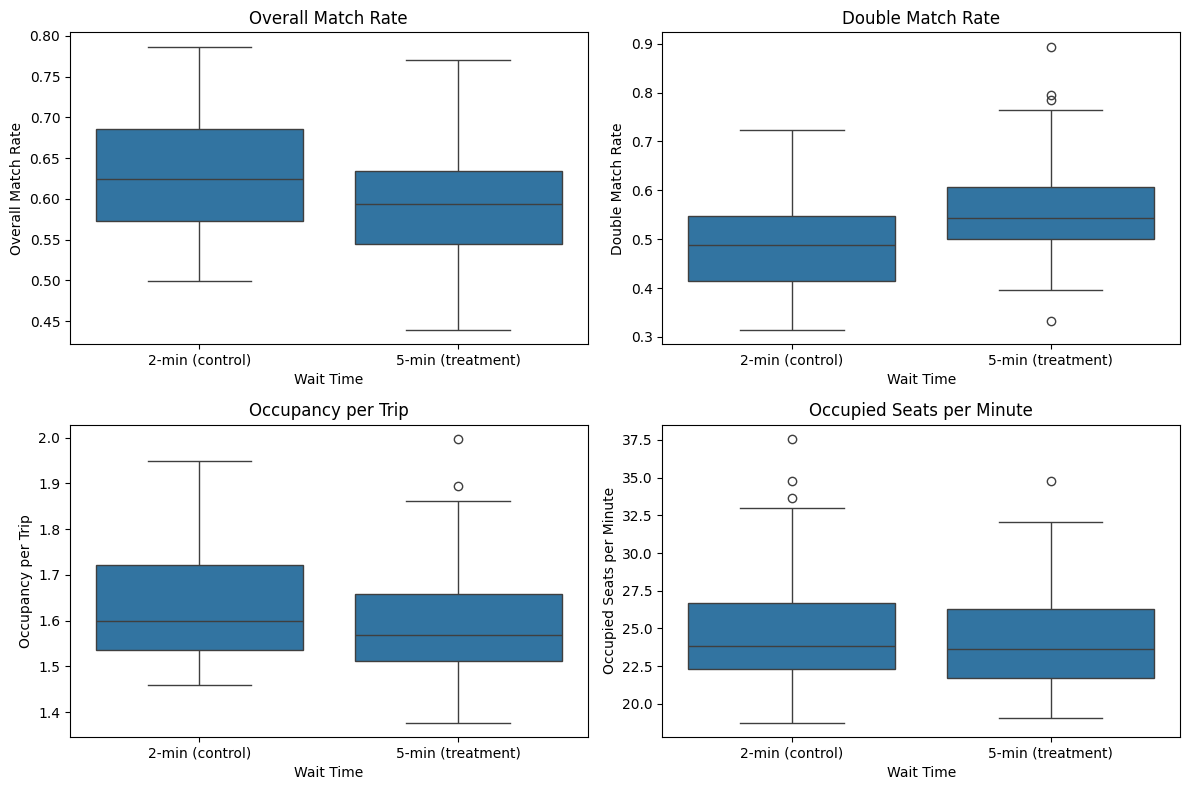

In [676]:
metrics_efficiency = [ #defining metrics
    "overall_match_rate",
    "double_match_rate",
    "occupancy_per_trip",
    "occupied_seats_per_min"
]

titles = [ #defining titles
    "Overall Match Rate",
    "Double Match Rate",
    "Occupancy per Trip",
    "Occupied Seats per Minute"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()  # making indexing easier

for i, metric in enumerate(metrics_efficiency): #iterating over metrics and their order
    sns.boxplot(
        data=df_uber,
        x="wait_label",
        y=metric,
        ax=axes[i]
    )
    
    axes[i].set_title(titles[i])
    axes[i].set_xlabel("Wait Time")
    axes[i].set_ylabel(titles[i])

plt.tight_layout()
plt.show()

The distributional analysis reinforces the earlier findings.Increasing wait time reduces the likelihood of forming shared matches, as seen in the lower overall match rate, but significantly increases full-capacity (three-rider) matches. This indicates a shift toward higher-quality matching. However, similar to previous finding,overall efficiency declines, with lower occupancy per trip and per minute which suggests that fewer riders are transported due to increased cancellations and reduced demand. Overall, the system trades match quantity for match quality, prioritizing denser trips at the expense of operational efficiency.

In [677]:
df_efficiency_plot = df_uber[[ #copying
    "hour", "segment", "treat","wait_label",
    "overall_match_rate",
    "double_match_rate",
    "occupancy_per_trip",
    "occupied_seats_per_min"
]].copy()

df_efficiency_melted = df_efficiency_plot.melt( #changing format
    id_vars=["hour", "segment", "treat","wait_label"],
    value_vars=[
        "overall_match_rate",
        "double_match_rate",
        "occupancy_per_trip",
        "occupied_seats_per_min"
    ],
    var_name="metric",
    value_name="value"
)

df_efficiency_melted = df_efficiency_melted.sort_values( #sorting
    ["segment", "treat", "metric", "hour","wait_label"]
)

df_efficiency_melted["metric"] = df_efficiency_melted["metric"].replace({ #renaming metrics
    "overall_match_rate": "Overall Match Rate",
    "double_match_rate": "Double Match Rate (Matches with 3 Riders)",
    "occupancy_per_trip": "Riders per Vehicle",
    "occupied_seats_per_min": "Occupied Seats per Minute"
})

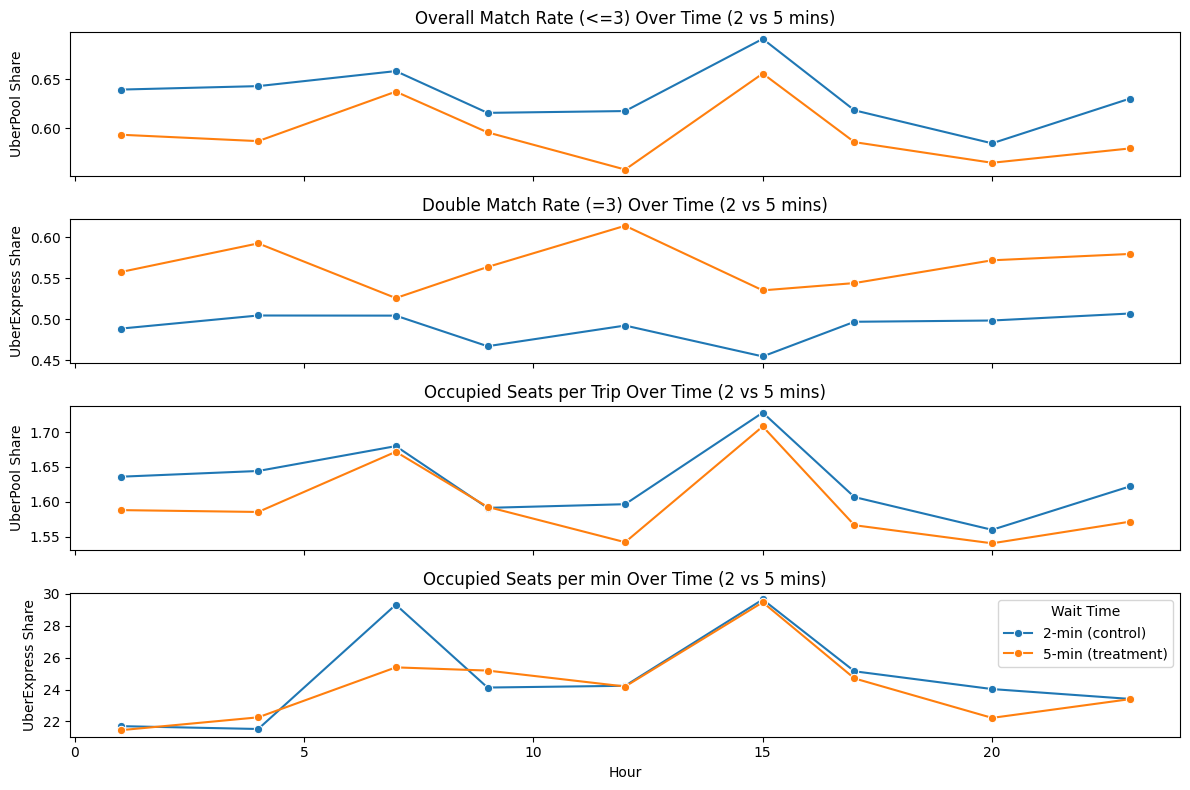

In [678]:
fig, axes = plt.subplots(4, 1, figsize=(12,8), sharex=True)

# Overall Match Rate
sns.lineplot(
    data=df_efficiency_melted[df_efficiency_melted["metric"] == "Overall Match Rate"],
    x="hour",
    y="value",
    hue="wait_label",
    errorbar=None,
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Overall Match Rate (<=3) Over Time (2 vs 5 mins)")
axes[0].set_ylabel("UberPool Share")
axes[0].set_xlabel("")

# Double Match Rate
sns.lineplot(
    data=df_efficiency_melted[df_efficiency_melted["metric"] == "Double Match Rate (Matches with 3 Riders)"],
    x="hour",
    y="value",
    hue="wait_label",
    errorbar=None,
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Double Match Rate (=3) Over Time (2 vs 5 mins)")
axes[1].set_ylabel("UberExpress Share")
axes[1].set_xlabel("Hour")

# Riders per Vehicle
sns.lineplot(
    data=df_efficiency_melted[df_efficiency_melted["metric"] == "Riders per Vehicle"],
    x="hour",
    y="value",
    hue="wait_label",
    errorbar=None,
    marker="o",
    ax=axes[2]
)

axes[2].set_title("Occupied Seats per Trip Over Time (2 vs 5 mins)")
axes[2].set_ylabel("UberPool Share")
axes[2].set_xlabel("")

# Occupied Seats per Minute
sns.lineplot(
    data=df_efficiency_melted[df_efficiency_melted["metric"] == "Occupied Seats per Minute"],
    x="hour",
    y="value",
    hue="wait_label",
    errorbar=None,
    marker="o",
    ax=axes[3]
)

axes[3].set_title("Occupied Seats per min Over Time (2 vs 5 mins)")
axes[3].set_ylabel("UberExpress Share")
axes[3].set_xlabel("Hour")

# legends only 1
axes[0].legend_.remove()
axes[1].legend_.remove()
axes[2].legend_.remove()
axes[3].legend(title="Wait Time")

plt.tight_layout()
plt.show()

The time-series analysis confirms that the observed trade-off is consistent across all hours. Longer wait times reduce the overall match rate while increasing full-capacity matches, indicating improved match quality. However, both occupancy per trip and seats per minute remain lower throughout the day, suggesting that overall system throughput declines. This reinforces the conclusion that the system consistently trades match quantity for match quality under the longer wait-time policy.

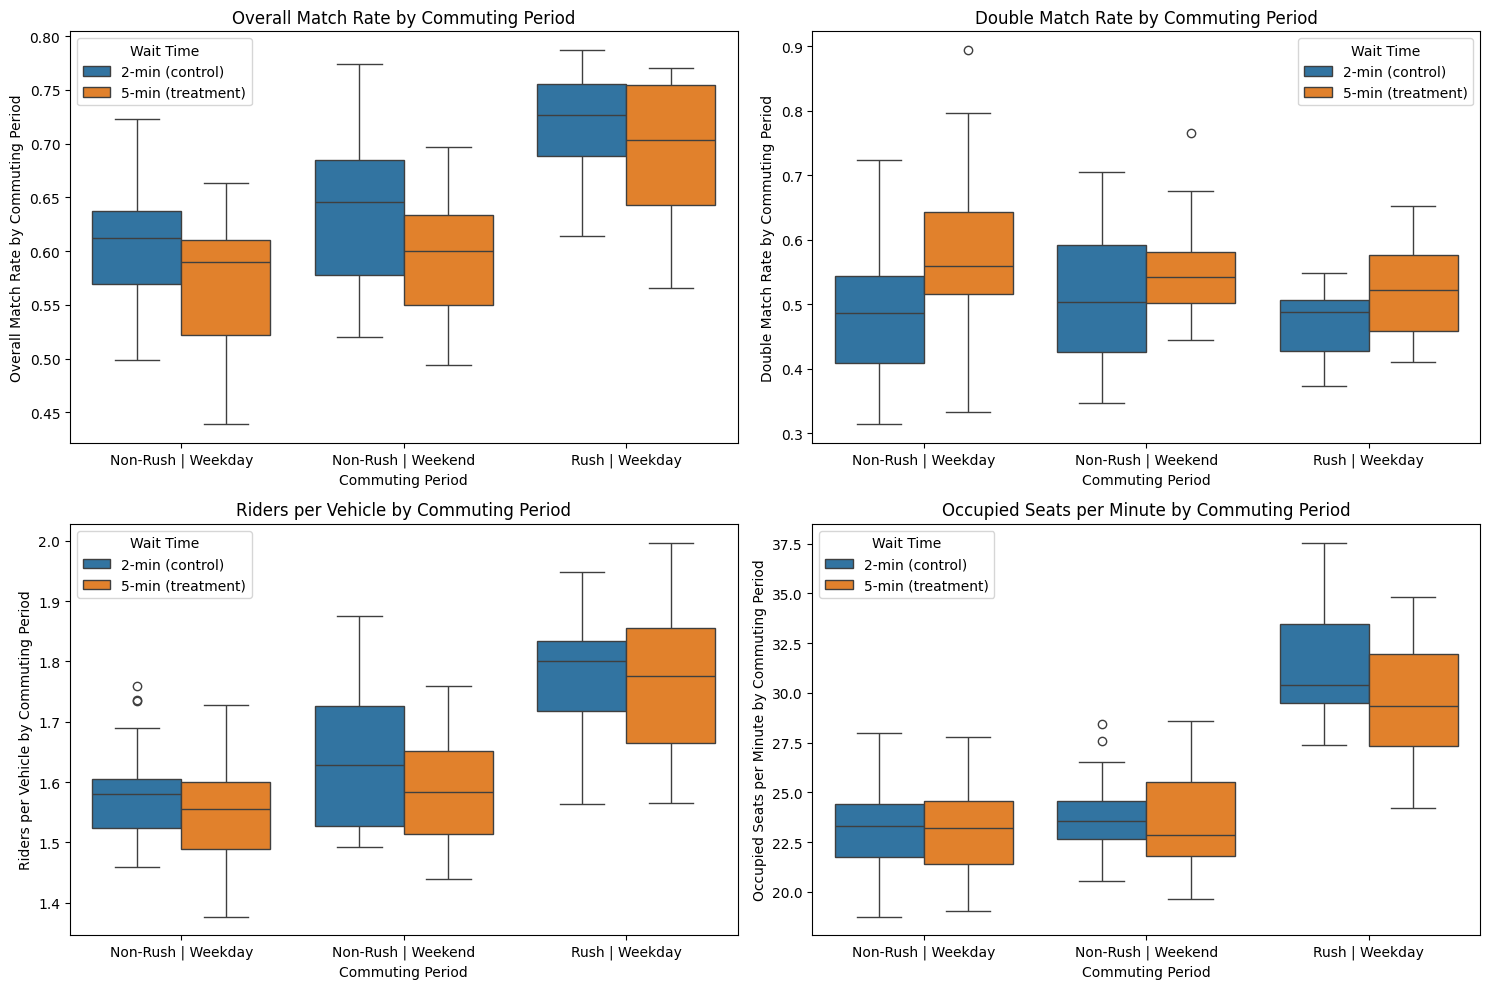

In [679]:
titles = [ #defining the new titles for existing defined metrics
    "Overall Match Rate by Commuting Period",
    "Double Match Rate by Commuting Period",
    "Riders per Vehicle by Commuting Period",
    "Occupied Seats per Minute by Commuting Period"
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()  # makes indexing easier

for i, metric in enumerate(metrics_efficiency): #forloofing over ith defined metrics
    sns.boxplot(
        data=df_uber,
        x="segment",
        y=metric,
        hue="wait_label",
        ax=axes[i]
    )
    
    axes[i].set_title(titles[i])
    axes[i].set_xlabel("Commuting Period")
    axes[i].set_ylabel(titles[i])
    axes[i].legend(title="Wait Time")

plt.tight_layout()
plt.show()



The segmented analysis shows that the longer wait-time policy consistently increases full-capacity matches across all commuting periods, confirming improved match quality. However, this comes at the cost of a lower overall match rate in every segment, with the largest declines observed during rush hours. Importantly, neither occupancy per trip nor occupied seats per minute improves under the longer wait policy; instead, both metrics decline across segments. The reduction in throughput is particularly pronounced during rush periods, where demand is highest and efficient utilization is most critical. This suggests that while the system becomes better at forming denser matches, it does so at the expense of overall efficiency, especially in high-urgency contexts.

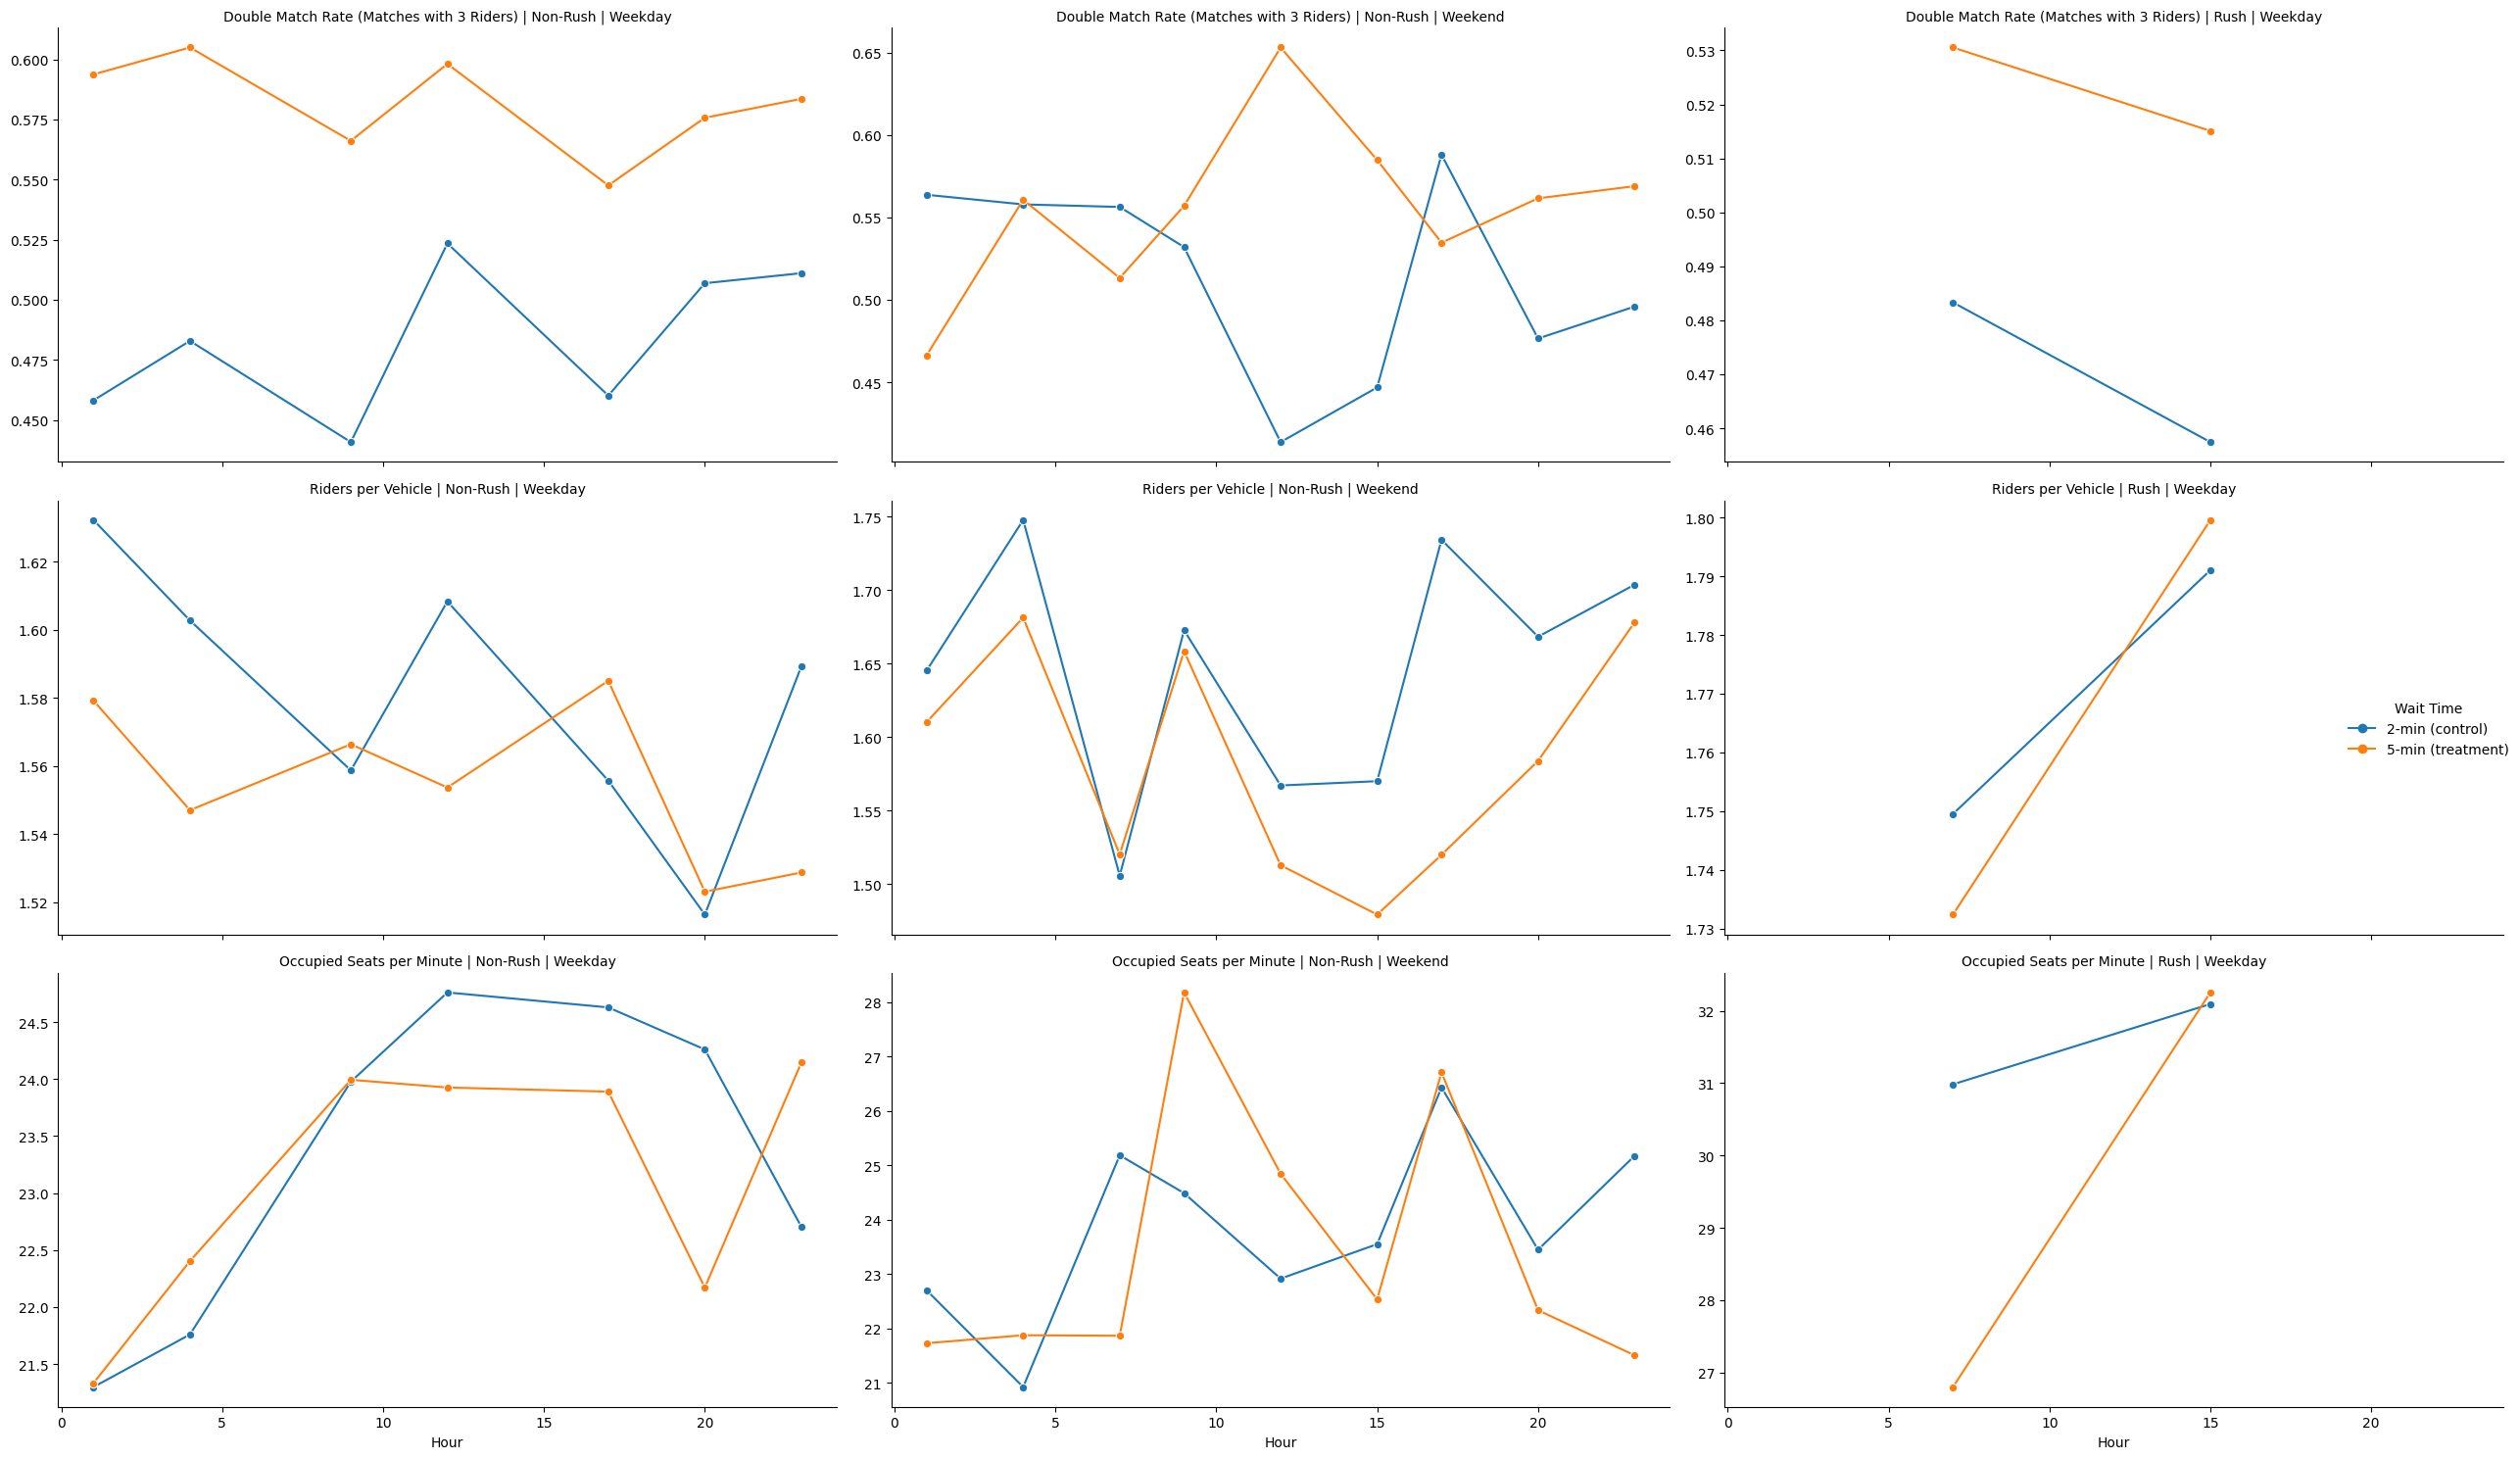

In [680]:
g = sns.relplot(
    data=df_efficiency_melted[df_efficiency_melted["metric"].isin(["Double Match Rate (Matches with 3 Riders)", "Riders per Vehicle", "Occupied Seats per Minute"])], #plot only these metrics
    x="hour",
    y="value",
    hue="wait_label",
    col="segment",          # columns = segments
    row="metric",           # rows = cancellation vs demand
    kind="line",
    height=5,
    aspect=1.6,
    errorbar=None,
    marker="o",
    facet_kws={"sharey": False} #flexible axis scale
)

# titles
g.set_titles("{row_name} | {col_name}")

# labels
g.set_axis_labels("Hour", "")
g._legend.set_title("Wait Time")

plt.tight_layout()
plt.show()

Similar to product mix segment difference results over time, occupancy patterns differ within rush hours, with evening periods showing relatively stronger performance under longer wait times compared to morning peaks. This likely reflects differences in rider time sensitivity, with morning commuters being less willing to wait, while evening riders are more flexible. However, these variations do not overturn the overall decline in system throughput.

## Driver cost per rider

In [681]:
#getting control treatment means
means_payout = df_uber.groupby("wait_time", observed=True)["driver_payout_per_trip"].mean()
means_cost = df_uber.groupby("wait_time", observed=True)["driver_cost_per_rider"].mean()

# % change from 2 to 5
pct_payout_change = (means_payout[5] - means_payout[2]) / means_payout[2] * 100
pct_cost_change = (means_cost[5] - means_cost[2]) / means_cost[2] * 100

#putting in one dataframe
df_cost = pd.DataFrame({
    "Metric": [
        "driver cost per trip",
        "driver cost per rider"
    ],
    "Mean (2 min)": [
        means_payout.loc[2],
        means_cost.loc[2]
    ],
    "Mean (5 min)": [
        means_payout.loc[5],
        means_cost.loc[5]
    ],
    "% Change": [
        pct_payout_change,
        pct_cost_change
    ]
})

df_cost.round(3)

,Metric,Mean (2 min),Mean (5 min),% Change
0,driver cost per trip,7.365,6.987,-5.124
1,driver cost per rider,11.326,11.357,0.268


Cost per trip captures efficiency at the vehicle level, reflecting how well riders are grouped within each trip. In contrast, cost per rider reflects efficiency at the system level, capturing how effectively the platform serves individual riders. In this analysis, the decline in cost per trip indicates improved grouping through higher-capacity matches. However, the lack of improvement in cost per rider suggests that these gains might be due to by reduced demand, increased cancellations, and fewer successful matches, limiting overall efficiency gains from the rider’s perspective.

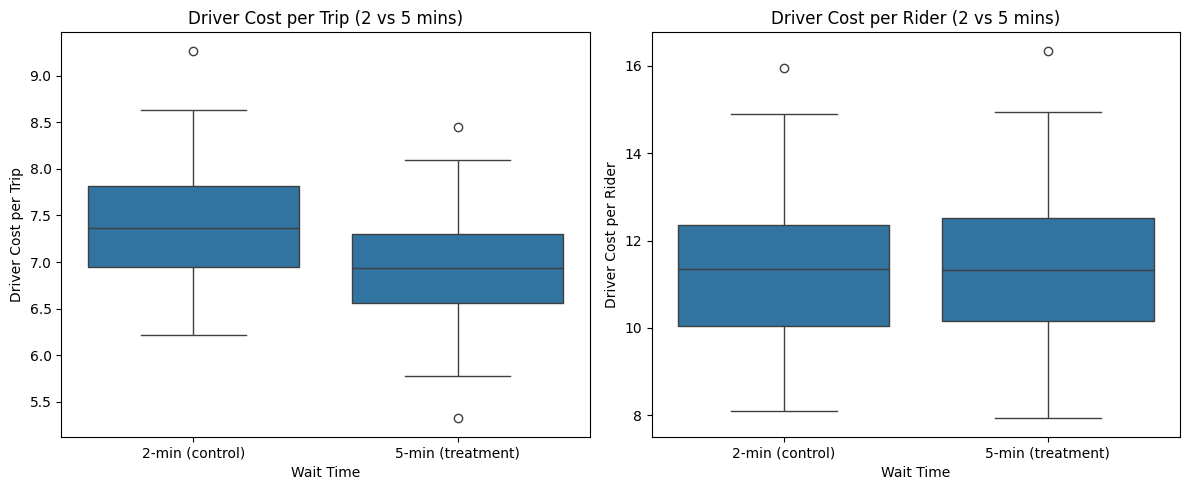

In [682]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

# Driver Cost per Trip
sns.boxplot(
    data=df_uber,
    x="wait_label",
    y="driver_payout_per_trip",
    ax=axes[0]
)
axes[0].set_title("Driver Cost per Trip (2 vs 5 mins)")
axes[0].set_xlabel("Wait Time")
axes[0].set_ylabel("Driver Cost per Trip")

# Driver Cost per Rider 
sns.boxplot(
    data=df_uber,
    x="wait_label",
    y="driver_cost_per_rider",
    ax=axes[1]
)
axes[1].set_title("Driver Cost per Rider (2 vs 5 mins)")
axes[1].set_xlabel("Wait Time")
axes[1].set_ylabel("Driver Cost per Rider")

plt.tight_layout()
plt.show()

The boxplots confirm that while the 5-minute policy reduces driver cost per trip, it does not reduce cost per rider. Specifically, the distribution of cost per trip under the 5-minute policy is consistently shifted downward, with a lower median and a tighter interquartile range compared to the 2-minute control. These indicate that more efficient and stable trip-level costs. In contrast, the cost per rider distributions for the two policies largely overlap, with nearly identical medians and similar spreads, suggesting no meaningful improvement in rider-level efficiency. This indicates that although trips are cheaper due to better pooling, these gains do not translate into lower costs per rider.

In [683]:
df_cost_plot = df_uber[[ #copying data
    "hour", "segment", "treat","wait_label",
    "driver_payout_per_trip",
    "driver_cost_per_rider"
]].copy()

df_cost_melted = df_cost_plot.melt( #formating the data
    id_vars=["hour", "segment", "treat","wait_label"],
    value_vars=["driver_payout_per_trip", "driver_cost_per_rider"],
    var_name="metric",
    value_name="value"
)

df_cost_melted = df_cost_melted.sort_values( #sorting
    ["segment", "treat", "metric", "hour","wait_label"]
)

df_cost_melted["metric"] = df_cost_melted["metric"].replace({ #renaming metrics
    "driver_payout_per_trip": "Driver Cost per Trip",
    "driver_cost_per_rider": "Driver Cost per Rider"
})

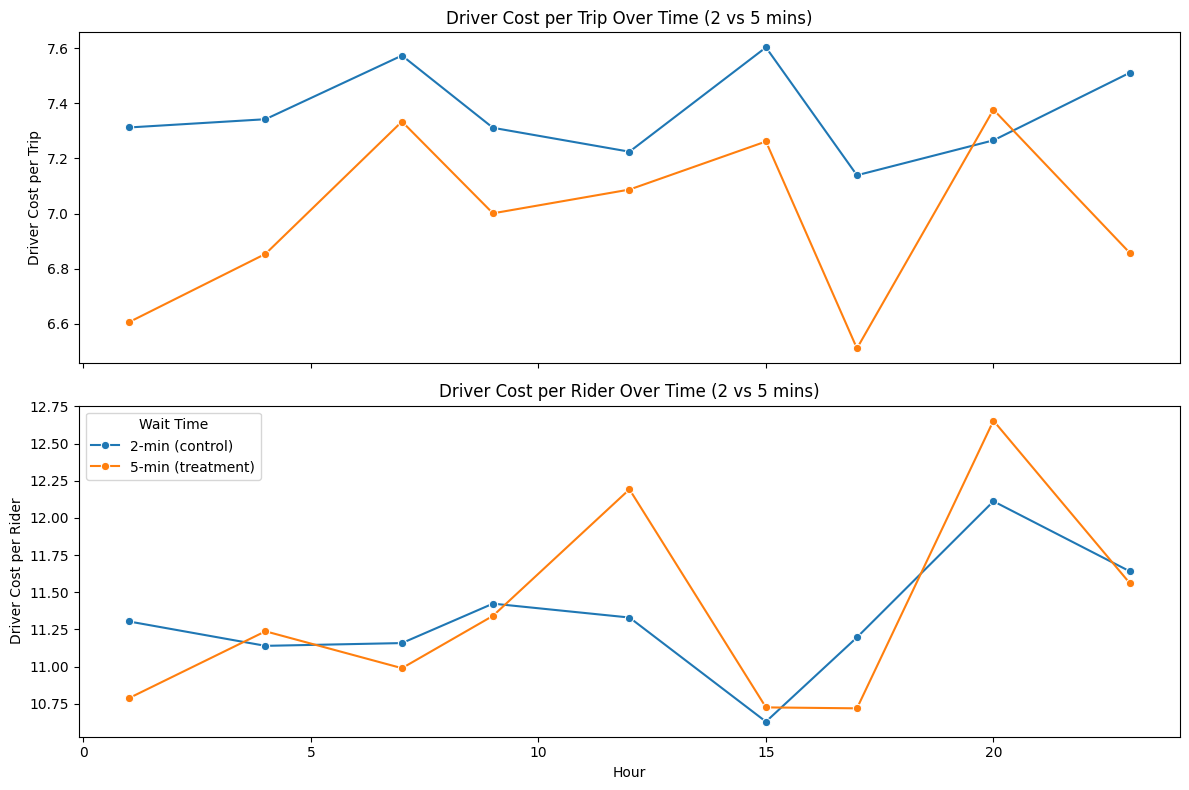

In [684]:
fig, axes = plt.subplots(2, 1, figsize=(12,8), sharex=True)

# Driver Cost per Trip
sns.lineplot(
    data=df_cost_melted[df_cost_melted["metric"] == "Driver Cost per Trip"],
    x="hour",
    y="value",
    hue="wait_label",
    errorbar=None,
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Driver Cost per Trip Over Time (2 vs 5 mins)")
axes[0].set_ylabel("Driver Cost per Trip")
axes[0].set_xlabel("")

# Driver Cost per Rider
sns.lineplot(
    data=df_cost_melted[df_cost_melted["metric"] == "Driver Cost per Rider"],
    x="hour",
    y="value",
    hue="wait_label",
    errorbar=None,
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Driver Cost per Rider Over Time (2 vs 5 mins)")
axes[1].set_ylabel("Driver Cost per Rider")
axes[1].set_xlabel("Hour")


# legends only 1
axes[0].legend_.remove()
axes[1].legend(title="Wait Time")

plt.tight_layout()
plt.show()

This pattern is also consistent over time. This plot revealed that cost per trip under the 5-minute policy remains below the 2-minute control across most hours, indicating stable trip-level efficiency gains throughout the day. In contrast, driver cost per rider fluctuates around similar levels for both policies, with no consistent downward shift under the 5-minute condition and even occasional increases during certain hours.

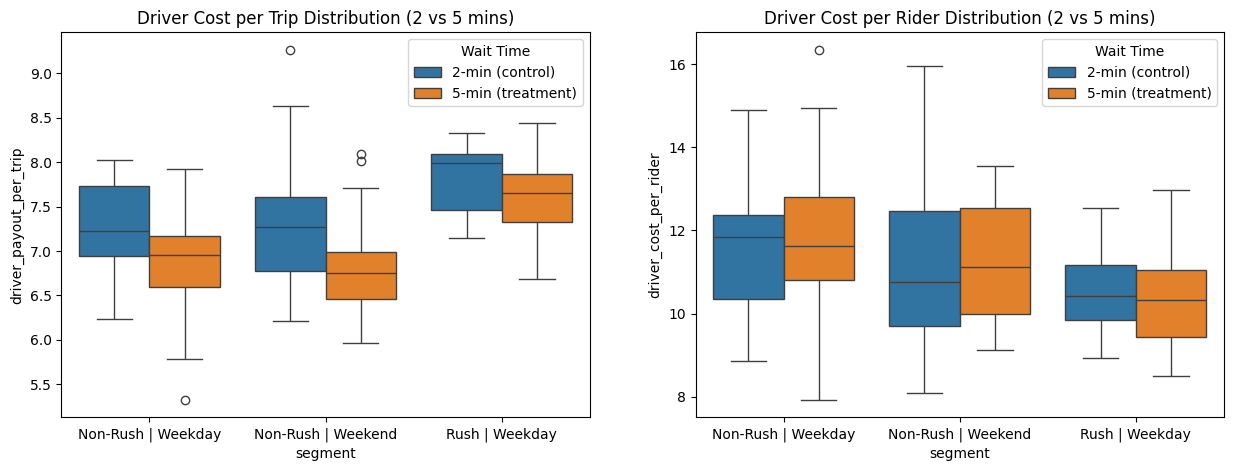

In [685]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Driver Cost per Trip
sns.boxplot(
    data=df_uber,
    x="segment",
    y="driver_payout_per_trip",
    hue="wait_label",
    ax=axes[0]
)
axes[0].set_title("Driver Cost per Trip Distribution (2 vs 5 mins)")
axes[0].legend(title="Wait Time")


# Driver Cost per Rider
sns.boxplot(
    data=df_uber,
    x="segment",
    y="driver_cost_per_rider",
    hue="wait_label",
    ax=axes[1]
)
axes[1].set_title("Driver Cost per Rider Distribution (2 vs 5 mins)")
axes[1].legend(title="Wait Time")

Driver cost per trip is consistently lower under the 5-minute policy across all commuting segments, with the treatment distributions generally shifted downward relative to the control. This suggests more efficient trip formation, particularly during non-rush periods where rider flexibility enables better grouping. In contrast, driver cost per rider shows substantial overlap between control and treatment across all segments, with similar medians and spreads. In some non-rush periods, the treatment even exhibits slightly higher variability, while during rush hours the distributions are nearly identical. This indicates that the improvements in trip-level efficiency do not translate into meaningful cost savings per rider.

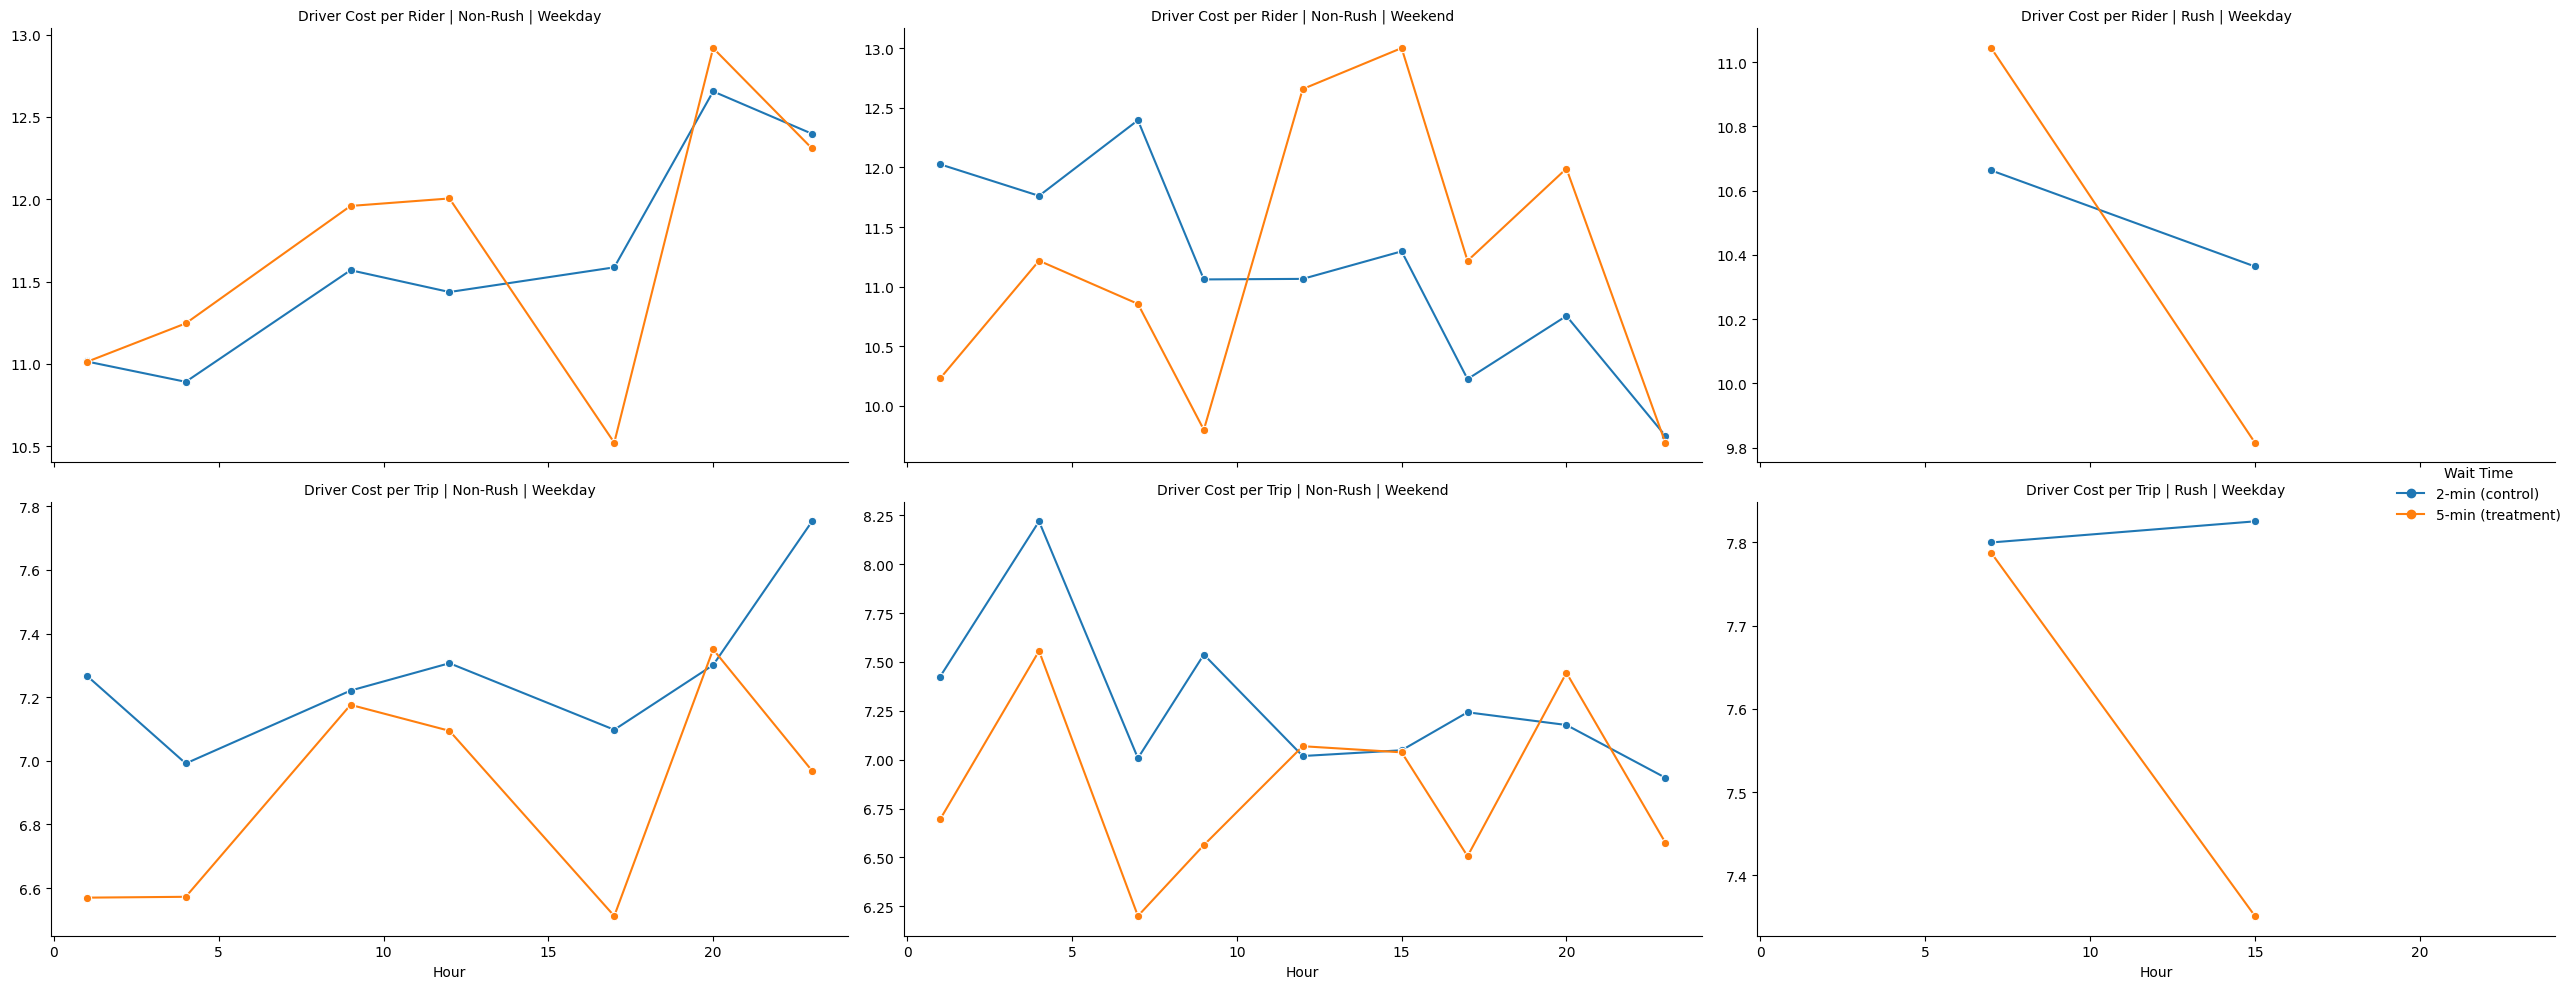

In [686]:
g = sns.relplot(
    data=df_cost_melted,
    x="hour",
    y="value",
    hue="wait_label",
    col="segment",          # columns = segments
    row="metric",           # rows = cancellation vs demand
    kind="line",
    height=5,
    aspect=1.6,
    errorbar=None,
    marker="o",
    facet_kws={"sharey": False} #flexible axis scale
)

# titles
g.set_titles("{row_name} | {col_name}")

# labels
g.set_axis_labels("Hour", "")

g._legend.set_title("Wait Time")


plt.tight_layout()
plt.show()

Driver cost per rider under the 5-minute policy varies noticeably over time during non-rush periods, showing fluctuations rather than a smooth or consistent decline. This suggests that while the policy improves matching opportunities, the realized cost efficiency still depends on hourly demand conditions. During rush hours, driver cost per trip under the 5-minute policy initially starts higher than the 2-minute control, indicating that longer wait times are not immediately effective in high-urgency conditions. Over time, however, both policies show declining costs, with the 5-minute treatment decreasing more rapidly. As a result, the gap between the two policies narrows and eventually reverses in some periods, suggesting that the efficiency gains from longer wait times materialize gradually rather than immediately. effects. Additionally, in non-rush weekday periods, the 2-minute control consistently results in higher cost per trip compared to the 5-minute treatment, indicating stable trip-level efficiency gains from the longer wait. However, during rush hours, the two policies start with very similar cost levels, and the gap widens over time, suggesting that the benefits of improved matching under the 5-minute policy materialize gradually rather than immediately.

# Hypothesis Tests and Regression Analysis

In the light of the initial EDA, below is our hypothesis:

### Table 3: Tested Hypothesis
| Hypothesis | Description |
|-----------|------------|
| **H1: Demand decreases under longer wait times** | Increasing wait time from 2 to 5 minutes reduces total ride requests, reflecting lower rider willingness to engage. |
| **H2: Customer experience worsens under longer wait times** | Longer wait times increase cancellation rates, indicating greater rider dissatisfaction and lower tolerance for delays. |
| **H3: Longer wait times shift riders toward pooling** | Increasing wait time reduces UberExpress share and increases UberPOOL share, reflecting a substitution effect driven by improved matching opportunities. |
| **H4: Longer wait times improve match quality but reduce match frequency** | Longer waits increase the double match rate (more 3-rider trips) but reduce the overall match rate (fewer riders matched at all), indicating a trade-off between match quality and quantity. |
| **H5: Longer wait times reduce overall system operational efficiency** | Despite improved match quality, occupancy per trip and occupied seats per minute decline, indicating that fewer riders are transported per vehicle and per unit time. |
| **H6: Longer wait times improve trip-level cost efficiency but not rider-level efficiency** | Longer waits reduce driver cost per trip but do not reduce cost per rider, suggesting that efficiency gains from better grouping are offset by reduced demand and increased cancellations. |

In [687]:
results = [] #empty list for results for later

def run_ttest_overall(metric, alternative="two-sided"): #defining a test function
    
    #defining control and treatment
    control = df_uber[df_uber["treat"] == 0][metric]
    treatment = df_uber[df_uber["treat"] == 1][metric]
    
    t_stat, p_value = stats.ttest_ind(treatment, control, equal_var=False)
    
    # adjustment (one-sided)
    if alternative == "less":
        p_value = p_value / 2 if t_stat < 0 else 1 - (p_value / 2)
    elif alternative == "greater":
        p_value = p_value / 2 if t_stat > 0 else 1 - (p_value / 2)
    
    results.append({ #results collecting
        "Metric": metric,
        "t_stat": round(t_stat, 3),
        "p_value": round(p_value, 5)
    })


# running all tests
run_ttest_overall("total_requests", "less")
run_ttest_overall("total_shared_trips", "less")
run_ttest_overall("cancellation_rate", "greater")
run_ttest_overall("pool_share", "greater")
run_ttest_overall("express_share", "less")
run_ttest_overall("overall_match_rate", "less")
run_ttest_overall("double_match_rate", "greater")
run_ttest_overall("occupancy_per_trip", "less")
run_ttest_overall("occupied_seats_per_min", "less")
run_ttest_overall("driver_payout_per_trip", "less")
run_ttest_overall("driver_cost_per_rider", "two-sided")


# summary table with all results
df_results = pd.DataFrame(results)

df_results

,Metric,t_stat,p_value
0,total_requests,-0.565,0.28647
1,total_shared_trips,-0.849,0.19867
2,cancellation_rate,5.521,0.00000
3,pool_share,3.444,0.00039
4,express_share,-3.444,0.00039
5,overall_match_rate,-2.925,0.00205
6,double_match_rate,4.213,0.00002
7,occupancy_per_trip,-1.568,0.05973
8,occupied_seats_per_min,-0.849,0.19867
9,driver_payout_per_trip,-3.462,0.00037


The initial hypothesis tests show that the 5-minute wait-time policy significantly changes rider behavior and matching dynamics. Despite this it has limited impact on overall demand and opperational efficiency. Total requests do not change significantly (p = 0.29), indicating that initial rider demand remains stable under longer wait times. Similarly, total shared trips—interpreted as realized demand—also show no significant change (p = 0.20), suggesting that the overall volume of completed rides is largely unaffected.

Despite stable demand, cancellation rates increase sharply (p < 0.001), indicating a clear deterioration in customer experience. This suggests that the primary impact of the policy occurs after riders enter the system, leading to higher abandonment rather than reduced initial engagement.

At the same time, there is a significant shift in ride composition, with UberPOOL share increasing and UberExpress share decreasing (both p < 0.001), confirming a strong substitution effect toward pooled rides. In terms of matching, the overall match rate declines (p < 0.01), while the double match rate increases (p < 0.001), indicating that the system forms fewer matches overall but prioritizes higher-capacity, three-rider trips when matches occur.

From an efficiency perspective, driver cost per trip decreases significantly (p < 0.001), reflecting improved trip-level efficiency. However, driver cost per rider remains unchanged (p = 0.92), and there is no significant change in occupied seats per minute (p = 0.20), indicating that system-level efficiency does not improve. Occupancy per trip shows only weak evidence of decline (p ≈ 0.06), suggesting limited changes in vehicle utilization.

Overall, the results highlight the fact that the 5-minute policy improves match quality and reduces cost per trip, but worsens customer experience and fails to improve overall system efficiency or demand.

In [688]:
results = [] #empty list for results for later

def run_ttest_collect(metric, alternative="two-sided"): #defining a test function
    
    for seg in df_uber["segment"].unique(): #iterating over segments
        
        df_seg = df_uber[df_uber["segment"] == seg]
        
        #defining control and treatment
        control = df_seg[df_seg["treat"] == 0][metric]
        treatment = df_seg[df_seg["treat"] == 1][metric]
        
        t_stat, p_value = stats.ttest_ind(treatment, control, equal_var=False)
        
        # adjustment (one-sided )
        if alternative == "less":
            p_value = p_value / 2 if t_stat < 0 else 1 - (p_value / 2)
        elif alternative == "greater":
            p_value = p_value / 2 if t_stat > 0 else 1 - (p_value / 2)
        
        # defining results
        results.append({
            "Metric": metric,
            "Segment": seg,
            "t_stat": round(t_stat, 3),
            "p_value": round(p_value, 5)
        })


# running all tests
run_ttest_collect("total_shared_trips", "less")
run_ttest_collect("cancellation_rate", "greater")
run_ttest_collect("pool_share", "greater")
run_ttest_collect("express_share", "less")
run_ttest_collect("overall_match_rate", "less")
run_ttest_collect("double_match_rate", "greater")
run_ttest_collect("occupancy_per_trip", "less")
run_ttest_collect("occupied_seats_per_min", "less")
run_ttest_collect("driver_payout_per_trip", "less")
run_ttest_collect("driver_cost_per_rider", "two-sided")


# creating a final table w all results
df_results = pd.DataFrame(results)

# Optional: sort nicely
df_results = df_results.sort_values(["Metric", "Segment"])

df_results

,Metric,Segment,t_stat,p_value
3,cancellation_rate,Non-Rush | Weekday,5.970,0.00000
4,cancellation_rate,Non-Rush | Weekend,1.924,0.03191
5,cancellation_rate,Rush | Weekday,6.839,0.00000
15,double_match_rate,Non-Rush | Weekday,3.761,0.00018
16,double_match_rate,Non-Rush | Weekend,1.344,0.09417
17,double_match_rate,Rush | Weekday,1.728,0.05144
27,driver_cost_per_rider,Non-Rush | Weekday,0.157,0.87582
28,driver_cost_per_rider,Non-Rush | Weekend,0.060,0.95255
29,driver_cost_per_rider,Rush | Weekday,-0.143,0.88758
24,driver_payout_per_trip,Non-Rush | Weekday,-2.983,0.00199


The segment-level hypothesis tests reveal that the effects of the 5-minute wait-time policy vary significantly across commuting conditions, highlighting important behavioral heterogeneity.

Cancellation rates increase significantly across all segments, with the strongest effects observed during rush hours and non-rush weekdays (p < 0.001), confirming that customer experience deteriorates consistently, especially in high-urgency periods.

The substitution toward pooling is strong and statistically significant in non-rush periods, where UberPOOL share increases and UberExpress share decreases (p < 0.05), but becomes insignificant during rush hours. This suggests that riders are less responsive to wait-time changes when time sensitivity is high, limiting the effectiveness of the policy in peak periods.

In terms of matching, the overall match rate declines significantly in non-rush segments (p < 0.05), while the increase in double match rate is strongest in non-rush weekdays and only weakly significant in other segments. This indicates that improvements in match quality are concentrated in more flexible, low-urgency environments.

From an efficiency perspective, driver cost per trip decreases significantly in non-rush periods but shows no significant improvement during rush hours which suggests that efficiency gains are context-dependent. Meanwhile, driver cost per rider remains unchanged across all segments.

Overall, these results indicate that the benefits of longer wait timesare primarily realized in non-rush periods, while the costs—particularly increased cancellations are present across all segments and most pronounced during rush hours. This implies that the policy is least effective in the periods where demand is highest and system performance is most critical.

### Table 4: Tested Hypothesis Results after t-tests
| Hypothesis | Results | Evaluation |
|-----------|--------|------------|
| **H1: Demand decreases** | Not supported | Total requests are not significantly different (p = 0.29), indicating no change in initial demand. |
| **H2: Customer experience worsens** | Supported | Cancellation rates increase significantly across all segments (p < 0.05, mostly < 0.001). |
| **H3: Substitution toward pooling** | Partially supported | Significant in non-rush periods, but not significant during rush hours. |
| **H4: Match quality ↑, match frequency ↓** | Partially supported | Overall match rate decreases significantly in non-rush, and double match increases, but effects are weaker or insignificant in rush periods. |
| **H5: Operational efficiency decreases** | Not supported | Occupied seats per minute is not significantly different across segments (mostly p > 0.05). |
| **H6: Trip cost ↓ but rider cost unchanged** | Partially supported | Cost per trip decreases significantly in non-rush but not in rush; cost per rider shows no significant change across all segments. |

In [689]:
outcomes = [
    "total_requests",
    "total_shared_trips",
    "cancellation_rate",
    "pool_share",
    "express_share",
    "overall_match_rate",
    "double_match_rate",
    "occupancy_per_trip",
    "occupied_seats_per_min",
    "driver_payout_per_trip",
    "driver_cost_per_rider"
]

rows = [] #empty list for results

def stars(p): #defining significance
    if pd.isna(p):
        return ""
    if p < 0.01:
        return "***"
    elif p < 0.05:
        return "**"
    elif p < 0.1:
        return "*"
    return ""

for var in outcomes: #iterating over outcomes fittin a seperate model for each outcome
    
    model = smf.ols( #model call w interaction treatment segment and effect of hour
        f"{var} ~ treat * C(segment) + C(hour)",
        data=df_uber
    ).fit(cov_type="HC1")
    
    # all hour dummy terms
    hour_terms = [term for term in model.params.index if term.startswith("C(hour)")]
    hour_pvalues = model.pvalues[hour_terms] if hour_terms else pd.Series(dtype=float)
    
    min_hour_p = hour_pvalues.min() if not hour_pvalues.empty else float("nan")
    any_hour_sig = (hour_pvalues < 0.05).any() if not hour_pvalues.empty else False
    
    rows.append({ #defining results all together neatly
        "Outcome": var,
        
        "Treat coef": round(model.params.get("treat", float("nan")), 4),
        "Treat p-value": round(model.pvalues.get("treat", float("nan")), 4),
        "Treat sig": stars(model.pvalues.get("treat", float("nan"))),
        
        "Treat×Segemnt coef": round(
            model.params.get("treat:C(segment)[T.Rush | Weekday]", float("nan")), 4
        ),
        "Treat×Segemnt p-value": round(
            model.pvalues.get("treat:C(segment)[T.Rush | Weekday]", float("nan")), 4
        ),
        "Treat×Segemnt sig": stars(
            model.pvalues.get("treat:C(segment)[T.Rush | Weekday]", float("nan"))
        ),
        
        "Segment coef": round(
            model.params.get("C(segment)[T.Non-Rush | Weekend]", float("nan")), 4
        ),
        "Segment p-value": round(
            model.pvalues.get("C(segment)[T.Non-Rush | Weekend]", float("nan")), 4
        ),
        "Segment sig": stars(
            model.pvalues.get("C(segment)[T.Non-Rush | Weekend]", float("nan"))
        ),
        
        "Min hour p-value": round(min_hour_p, 4),
        "Hour sig": stars(min_hour_p),
        "Any hour significant": "Yes" if any_hour_sig else "No",
        
        "R-squared": round(model.rsquared, 4)
    })

df_reg_final = pd.DataFrame(rows) #putting results in data frame

df_reg_final

,Outcome,Treat coef,Treat p-value,Treat sig,Treat×Segemnt coef,Treat×Segemnt p-value,Treat×Segemnt sig,Segment coef,Segment p-value,Segment sig,Min hour p-value,Hour sig,Any hour significant,R-squared
0,total_requests,-11.7143,0.8898,,-253.8857,0.2606,,109.3270,0.2668,,0.0000,***,Yes,0.6798
1,total_shared_trips,-34.8571,0.6679,,-287.0429,0.1751,,103.2849,0.2775,,0.0000,***,Yes,0.6629
2,cancellation_rate,0.0062,0.0000,***,0.0080,0.0005,***,0.0004,0.8427,,0.2417,,No,0.6438
3,pool_share,0.0293,0.0209,**,-0.0036,0.8904,,-0.0483,0.0001,***,0.0005,***,Yes,0.3556
4,express_share,-0.0293,0.0209,**,0.0036,0.8904,,0.0483,0.0001,***,0.0005,***,Yes,0.3556
5,overall_match_rate,-0.0371,0.0074,***,0.0128,0.6862,,0.0499,0.0110,**,0.0018,***,Yes,0.4382
6,double_match_rate,0.0980,0.0003,***,-0.0456,0.2587,,0.0340,0.2704,,0.4996,,No,0.1734
7,occupancy_per_trip,-0.0257,0.1880,,0.0214,0.7134,,0.0929,0.0030,***,0.0005,***,Yes,0.4641
8,occupied_seats_per_min,-0.2179,0.6679,,-1.7940,0.1751,,0.6455,0.2775,,0.0000,***,Yes,0.6629
9,driver_payout_per_trip,-0.3849,0.0025,***,0.1417,0.5773,,0.0802,0.7260,,0.1153,,No,0.2701


The segment- based regression results indicate that the 5-minute wait-time policy has no statistically significant effect on demand, as both total requests (β = −11.71, p = 0.89) and total shared trips (β = −34.86, p = 0.67) are small and insignificant, providing strong evidence that demand remains unchanged.

However,there is strong evidence of a deterioration in customer experience. The cancellation rate increases significantly (β = 0.0062, p < 0.001), with a further significant increase in certain segments (β = 0.0080, p < 0.001), indicating that the policy leads to higher rider drop-off in some contexts.

A statistically significant substitution effect is observed, with pool share increasing (β = 0.0293, p = 0.021) and express share decreasing (β = −0.0293, p = 0.021). The lack of significant interaction effects suggests that this shift is consistent across segments.

Matching outcomes reveal that while overall match rate declines (β = −0.0371, p = 0.007), double match rate increases (β = 0.0980, p < 0.001). This indicates that fewer but more efficient high-capacity matches.

Efficiency results remain weak. There is no evidence of improved throughput, as occupied seats per minute is insignificant (p = 0.67), and occupancy per trip is also not significant (p = 0.19). While driver payout per trip decreases (β = −0.3849, p = 0.003), driver cost per rider remains unchanged (p = 0.87), suggesting no system-level efficiency gains.

Finally, while segment-level heterogeneity is limited, hour effects are consistently strong and highly significant across most outcomes (p ≈ 0.000). This indicates that time-of-day variation is a key driver of system performance, often more important than segment differences.

In [690]:
rows = [] #empty rows list

def stars(p): #significance
    if pd.isna(p):
        return ""
    if p < 0.01:
        return "***"
    elif p < 0.05:
        return "**"
    elif p < 0.1:
        return "*"
    return ""

for var in outcomes:
    
    model = smf.ols(
        f"{var} ~ treat * commute + C(hour)", #now doing for treatment commute interaction w effect of hout
        data=df_uber
    ).fit(cov_type="HC1")
    
    rows.append({ #results neatly in empty list
        "Outcome": var,
        
        "Treat coef": round(model.params.get("treat", float("nan")), 4),
        "Treat p-value": round(model.pvalues.get("treat", float("nan")), 4),
        "Treat sig": stars(model.pvalues.get("treat", float("nan"))),

        "Treat×Commute coef": round(
            model.params.get("treat:commute", float("nan")), 4
        ),
        "Treat×Commute p-value": round(
            model.pvalues.get("treat:commute", float("nan")), 4
        ),
        "Treat×Commute sig": stars(
            model.pvalues.get("treat:commute", float("nan"))
        ),

        "Commute coef": round(
            model.params.get("commute", float("nan")), 4
        ),
        "Commute p-value": round(
            model.pvalues.get("commute", float("nan")), 4
        ),
        "Commute sig": stars(
            model.pvalues.get("commute", float("nan"))
        ),

        "Min hour p-value": round(min_hour_p, 4),
        "Hour sig": stars(min_hour_p),
        "Any hour significant": "Yes" if any_hour_sig else "No",
        
        "R-squared": round(model.rsquared, 4)
    })

df_reg_final = pd.DataFrame(rows) #final table w results

df_reg_final

,Outcome,Treat coef,Treat p-value,Treat sig,Treat×Commute coef,Treat×Commute p-value,Treat×Commute sig,Commute coef,Commute p-value,Commute sig,Min hour p-value,Hour sig,Any hour significant,R-squared
0,total_requests,-23.7358,0.7234,,-241.8642,0.2672,,1404.7821,0.0000,***,0.0897,*,No,0.6761
1,total_shared_trips,-42.5660,0.5106,,-279.3340,0.1715,,1298.8420,0.0000,***,0.0897,*,No,0.6587
2,cancellation_rate,0.0052,0.0000,***,0.0090,0.0001,***,0.0100,0.0000,***,0.0897,*,No,0.6333
3,pool_share,0.0357,0.0004,***,-0.0100,0.6877,,-0.0802,0.0000,***,0.0897,*,No,0.2785
4,express_share,-0.0357,0.0004,***,0.0100,0.6877,,0.0802,0.0000,***,0.0897,*,No,0.2785
5,overall_match_rate,-0.0404,0.0007,***,0.0161,0.6001,,0.1358,0.0000,***,0.0897,*,No,0.3794
6,double_match_rate,0.0787,0.0001,***,-0.0262,0.4707,,-0.0156,0.7302,,0.0897,*,No,0.1591
7,occupancy_per_trip,-0.0385,0.0299,**,0.0343,0.5504,,0.2323,0.0000,***,0.0897,*,No,0.3976
8,occupied_seats_per_min,-0.2660,0.5106,,-1.7458,0.1715,,8.1178,0.0000,***,0.0897,*,No,0.6587
9,driver_payout_per_trip,-0.4027,0.0004,***,0.1595,0.5170,,0.7877,0.0005,***,0.0897,*,No,0.2686


The regression results show that the 5-minute wait-time policy has no statistically significant effect on demand, as total requests (β = −23.74, p = 0.72) and total shared trips (β = −42.57, p = 0.51) are small and insignificant, indicating no impact on either initial or realized demand.

There is strong evidence of worsening customer experience, with cancellations increasing significantly (β = 0.0052, p < 0.001), and even more during commute periods (β = 0.0090, p < 0.001), suggesting greater sensitivity in rush hours.

A clear substitution effect is observed, with pool share increasing (β = 0.0357, p < 0.001) and express share decreasing (β = −0.0357, p < 0.001). These effects are highly significant and consistent across commute conditions.

Matching outcomes reveal a trade-off, as overall match rate declines (β = −0.0404, p < 0.001) while double match rate increases (β = 0.0787, p < 0.001), indicating fewer but more efficient matches.

Efficiency effects remain limited: occupied seats per minute is not significant (p = 0.51), and while occupancy per trip declines slightly (β = −0.0385, p = 0.03), driver cost per rider shows no change (p = 0.87). Although driver payout per trip decreases (β = −0.4027, p < 0.001), gains are limited to the trip level.

Heterogeneity across commute is minimal, with only cancellations showing a significant interaction. Hour effects are weak (p ≈ 0.09) and not jointly significant, indicating that time-of-day variation is less important once commute is accounted for.

### Table 5: Tested Hypothesis Results after Regression Analysis
| Hypothesis | Result | Evaluation |
|-----------|--------|-----------|
| **H1: Demand decreases** | Not supported | total_requests (p = 0.72) and total_shared_trips (p = 0.51) show no significant or meaningful decline. |
| **H2: Customer experience worsens**  | Strongly supported | cancellation_rate increases significantly (p < 0.001), with an even larger effect in commute periods (p < 0.001). |
| **H3: Substitution toward pooling** | Strongly supported | pool_share increases and express_share decreases (both p < 0.001), indicating a clear substitution effect. |
| **H4: Match quality ↑, match frequency ↓**  | Partially supported | double_match_rate increases (p < 0.001) but overall_match_rate decreases (p < 0.001), confirming a trade-off rather than pure improvement. |
| **H5: Operational efficiency decreases** | Supported | no improvement in operational efficiency (occupied_seats_per_min p = 0.51) and a decline in occupancy_per_trip (p = 0.03) indicate reduced efficiency. |
| **H6: Trip cost ↓ but rider cost unchanged**  | Supported | driver_payout_per_trip decreases (p < 0.001), but driver_cost_per_rider is not significant (p = 0.87), showing gains only at the trip level. |

Overall Results

### Table 6: Tested Hypothesis Results Consensus

| Hypothesis | Overall Consensus | Explanation |
|------------------|------------------|-------------|
| **H1: Demand decreases under longer wait times** | Not supported | Both hypothesis testing and regression show no meaningful change in demand. |
| **H2: Customer experience worsens under longer wait times** | Supported | Both hypothesis testing and regression show increased cancellations. |
| **H3: Longer wait times shift riders toward pooling** | Supported | Regression strongly supports this, while hypothesis testing shows weaker but consistent directional evidence. |
| **H4: Longer wait times improve match quality but reduce match frequency** | Supported | Both methods confirm the trade-off: higher-quality matches but fewer matches overall. |
| **H5: Longer wait times reduce overall system operational efficiency** | Partially supported | Regression shows a decline in efficiency, while hypothesis testing does not find a clear effect. |
| **H6: Longer wait times improve trip-level cost efficiency but not rider-level efficiency**| Supported | Both methods show improvement at the trip level but no improvement per rider. |

#### Additional Findings: 
- AF1: Policy effects are largely consistent across conditions The treatment effects do not significantly differ across segments or commute conditions, as most interaction terms are statistically insignificant (p > 0.10). 
- AF2: Cancellations exhibit meaningful heterogeneity The increase in cancellation rates is significantly larger in commute periods (β = 0.0090, p < 0.001), indicating that rider sensitivity to wait time is higher during rush hours. 
- AF3: Time-of-day effects dominate segment effects Hour effects are consistently highly significant in the segment-based model (p ≈ 0.000), suggesting strong temporal variation in system outcomes. 
- AF4: Segment-level heterogeneity is partly driven by time variation The reduced significance of hour effects in the commute model (p ≈ 0.09) indicates that simpler commute structure captures much of the time-related variation.

### Tree Based Robustness Analysis

This analysis is conducted to reveal which effect is dominant.

In [691]:
# copying data
df_tree = df_uber.copy()

# ensuring treat and commute are numeric
df_tree["treat"] = df_tree["treat"].astype(int)
df_tree["commute"] = df_tree["commute"].astype(int)

# definingfeatures
X = pd.get_dummies(
    df_tree[["treat", "commute", "hour"]],
    columns=["hour"],
    drop_first=False
)
#defining outcome
y = df_tree["cancellation_rate"]

In [692]:
parameters = { #tuning parameters
    "max_depth": [3, 5, 7],
    "min_samples_leaf": [3, 5, 10],
    "n_estimators": [200, 300,400,500]
}

rf_model = RandomForestRegressor(random_state=42) #defining model

grid_search = GridSearchCV( #hyperparameter tuning with grid searching for best model
    rf_model,
    parameters,
    cv=3,
    scoring="neg_mean_squared_error", #doing for regression
    n_jobs=-1
)

grid_search.fit(X, y) #fitting grid search

best_model = grid_search.best_estimator_ #getting best match

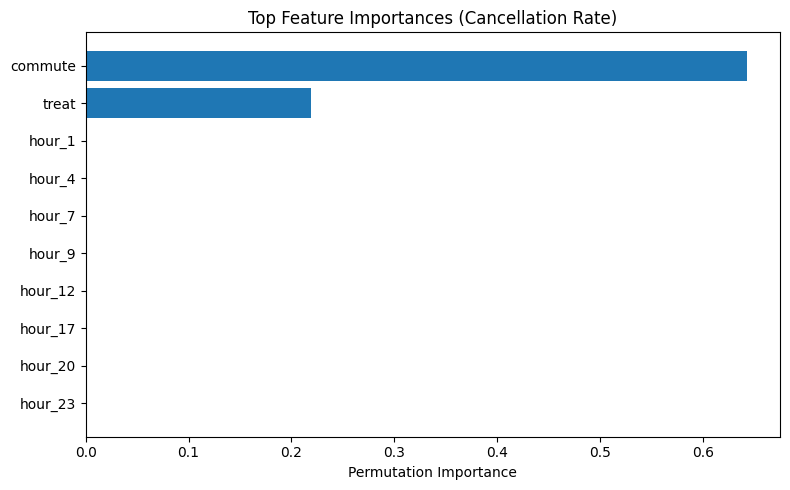

In [693]:
#getting permutation importances 
perm = permutation_importance( 
    best_model,
    X,
    y,
    n_repeats=30,
    random_state=42
)

# plotting
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=False)

imp_features = importance_df.head(10)

plt.figure(figsize=(8,5))
plt.barh(imp_features["Feature"][::-1], imp_features["Importance"][::-1])
plt.title("Top Feature Importances (Cancellation Rate)")
plt.xlabel("Permutation Importance")
plt.ylabel("")
plt.tight_layout()
plt.show()

The Random Forest feature importance results show that commute is by far the most important predictor of cancellation rates, with a substantially higher importance score than all other variables. This indicates that whether a trip occurs during rush (commute) periods is the dominant factor driving variation in cancellations. The treatment variable (wait time policy) is the second most important feature, suggesting that the 5-minute wait-time policy has a meaningful impact on cancellation behavior, though its effect is considerably smaller than that of commute conditions. In contrast, hour-of-day variables have negligible importance, with near-zero contribution to predictive performance. This suggests that fine-grained time-of-day variation does not significantly explain cancellation behavior once commute structure is accounted for.

##### Revised AF3 and AF4
- AF3: Commute effects dominate fine-grained time variation
While earlier results suggested strong hour effects, tree-based feature importance shows that commute is the dominant driver of variation in cancellations, with hour playing a minimal role.

- AF4: Segment-level heterogeneity is not strongly supported after controlling for structure
Although segment-based analysis suggests some variation, regression results show limited statistically significant differences, and tree-based results indicate that most variation is explained by commute rather than more granular segmentation.

# Experimental Design Discussion

To asses different types of product improvements, Uber relied on multiple types of experiments when developing Express POOL. Algorithims behind the products affect all users in a given are simultaneously. Therefore, Uber utilised highly localized experimental designs (like switchbacks) to test the appropreateness of the algorithms. Also, broader designs (like synthetic controls) enabled Uber to measure the impact of a new product on market dynamics. More specifically, while Boston Wait-Time Experiment allows to test the impact of increasing wait times from 2 to 5 minutes by alternating the algorithm every 160 minutes, 12-City Launch Experiment evaluates the broader impact of the Express product on market outcomes.

There is an ongoing debate about whether to introduce the Boston-inspired five-minute wait time into the 12-city experiment in the light of early findings which suggests that longer wait times may improve matching efficiency and product performance. However, this introducing increased wait times midway through the ongoing 12-city experiment rises concerns of inbility to accurately evaluate the true impact of the Express POOL launch due to added confounfing factors. This would result in increased risk of loosing access to a highly valuable and clean experiment data, resulting in reduced the precision of the results. When the initial goal of 12-city experiment is concidered, isolating the impact of the Express POOL product with a fixed two-minute wait time, increasing wait times might result in mixture of two different treatments within the same group. Therefore, Uber cannot confidently identify whether the underlying reason of performance or cost changes is due to the product itself or longer wait times. Also further bias would be introduced since treatment cities would no longer be comparable to the control cities since control cities are unchanged. Furthermore, inference and instability would be introduced over time since user behaviour may show differences before and after the change. 

# Recommendation to Uber

Our final recommendation to Stock would be to keep the two-minute wait time until the 12-city launch experiment ends, and then pursue a structured follow-up experiment to evaluate targeted longer wait times. Our primary reason is experimental integrity for which Uber should ensure clean baseline measurements under five-week freeze to be able to determine the source of observed outcomes. As also mentioned in the case, Uber only gets one opportunity to collect clean baseline data. By risking to conraminating this data, Uber also risks undermining all subsequent decisions based on these experiments. Our analysis also supported this concern by revealing a clear deterioration in customer experience. At the same time we have discovered a strong network-driven substitution effect. Riders shift drom Express to UberPool which reflects improved matching opportunities, as longer waits allow the system to group riders more effectively. Hiwever these effects are limited since we couldnt identify system-wide efficiency improvements. 

Interestingly, our findings revealed a more nuanced opportunity. The strong heterogeneity appers across multiple metrics, especially during commute periods, suggests that targated waittime policy might be beneficial. For example, Uber can increase wait times only during commute periods where demands is high and keep the non-commute periods two minutes. However, implementing such a dynamic policy within the current experiment would further confound results and undermine causal identification.

Therefore, Uber should take a sequential approach to implement the new suggested strategy. Firstly, they should complete 12-city experiment with five-week freeze period under two minute wait times in order to get a clean and interpretable baseline data on UberExpress impact. Later, a follow up experiment should be conducted to test longer wait times including targeted wait times.This preserves the integrity of the original experiment while allowing Uber to capture potential efficiency gains in a controlled and credible way.

## The back-of-the-envelope analysis for our recommendation

The back-of-the-envelope analysis indicates that the 5-minute wait time policy consistently generates positive net gains relative to the 2-minute baseline, driven by substantial reductions in driver payout per trip. Across all tested assumptions, the net effect remains positive, though it declines sharply as the assumed value per lost trip increases. This pattern shows that even if cost savings initially higher than targeted approach, the economic advantage is highly sensitive to demand-side losses. This reflects a clear trade-off between efficiency and demand retention. In contrast, the hybrid policy (5 minutes during commute, 2 minutes otherwise) performs poorly (net_effect <0), as its limited cost savings are insufficient to offset even smaller demand losses. Overall, while the results suggest that a 5-minute wait time may be profitable in short-term accounting terms, the rapid decline in net gains indicates diminishing returns. Collectively these imply that 5 minute may not be the optimal policy and that a more balanced or targeted approach could potentially yield better outcomes.

In [694]:
# policy 1: baseline = 2-minute wait everywhere
df_base = df_uber[df_uber["treat"] == 0].copy()

# policy 2: 5-minute wait everywhere
df_5_all = df_uber[df_uber["treat"] == 1].copy()

# policy 3: hybrid
# - commute periods use 5-minute, non-commute periods use 2-minute observations
df_hybrid = pd.concat([
    df_uber[(df_uber["commute"] == 1) & (df_uber["treat"] == 1)],
    df_uber[(df_uber["commute"] == 0) & (df_uber["treat"] == 0)]
]).copy()

# mean outcomes for each policy
base_trips = df_base["total_shared_trips"].mean()
all5_trips = df_5_all["total_shared_trips"].mean()
hybrid_trips = df_hybrid["total_shared_trips"].mean()

base_cost_per_trip = df_base["driver_payout_per_trip"].mean()
all5_cost_per_trip = df_5_all["driver_payout_per_trip"].mean()
hybrid_cost_per_trip = df_hybrid["driver_payout_per_trip"].mean()

# assumed revenue per lost trip
revenue_per_lost_trip_scenarios = [5, 8, 10,13]

results = [] #empty list for results

for rev in revenue_per_lost_trip_scenarios: #iterating over different senarios (assumed revenue per lost trip)
    
    # 5 min everywhere vs baseline
    all5_cost_saving_per_trip = base_cost_per_trip - all5_cost_per_trip
    all5_lost_trips = base_trips - all5_trips
    all5_gross_cost_saving = all5_cost_saving_per_trip * all5_trips
    all5_lost_revenue = all5_lost_trips * rev
    all5_net_effect = all5_gross_cost_saving - all5_lost_revenue
    
    results.append({ #results 5 mins
        "policy": "5min_everywhere",
        "assumed_revenue_per_lost_trip": rev,
        "baseline_trips_2min_everywhere": round(base_trips, 2),
        "policy_trips": round(all5_trips, 2),
        "lost_trips": round(all5_lost_trips, 2),
        "baseline_cost_per_trip": round(base_cost_per_trip, 4),
        "policy_cost_per_trip": round(all5_cost_per_trip, 4),
        "cost_saving_per_trip": round(all5_cost_saving_per_trip, 4),
        "gross_cost_saving": round(all5_gross_cost_saving, 2),
        "lost_revenue": round(all5_lost_revenue, 2),
        "net_effect": round(all5_net_effect, 2)
    })
    
    # hybrid vs baseline 
    hybrid_cost_saving_per_trip = base_cost_per_trip - hybrid_cost_per_trip
    hybrid_lost_trips = base_trips - hybrid_trips
    hybrid_gross_cost_saving = hybrid_cost_saving_per_trip * hybrid_trips
    hybrid_lost_revenue = hybrid_lost_trips * rev
    hybrid_net_effect = hybrid_gross_cost_saving - hybrid_lost_revenue
    
    results.append({ #results hybrid
        "policy": "5min_commute_2min_noncommute",
        "assumed_revenue_per_lost_trip": rev,
        "baseline_trips_2min_everywhere": round(base_trips, 2),
        "policy_trips": round(hybrid_trips, 2),
        "lost_trips": round(hybrid_lost_trips, 2),
        "baseline_cost_per_trip": round(base_cost_per_trip, 4),
        "policy_cost_per_trip": round(hybrid_cost_per_trip, 4),
        "cost_saving_per_trip": round(hybrid_cost_saving_per_trip, 4),
        "gross_cost_saving": round(hybrid_gross_cost_saving, 2),
        "lost_revenue": round(hybrid_lost_revenue, 2),
        "net_effect": round(hybrid_net_effect, 2)
    })

df_policy_compare = pd.DataFrame(results) #combining in one data frame
df_policy_compare

,policy,assumed_revenue_per_lost_trip,baseline_trips_2min_everywhere,policy_trips,lost_trips,baseline_cost_per_trip,policy_cost_per_trip,cost_saving_per_trip,gross_cost_saving,lost_revenue,net_effect
0,5min_everywhere,5,3966.98,3880.08,86.9,7.3649,6.9875,0.3774,1464.37,434.52,1029.85
1,5min_commute_2min_noncommute,5,3966.98,3915.89,51.1,7.3649,7.3263,0.0386,151.20,255.48,-104.28
2,5min_everywhere,8,3966.98,3880.08,86.9,7.3649,6.9875,0.3774,1464.37,695.24,769.14
3,5min_commute_2min_noncommute,8,3966.98,3915.89,51.1,7.3649,7.3263,0.0386,151.20,408.76,-257.56
4,5min_everywhere,10,3966.98,3880.08,86.9,7.3649,6.9875,0.3774,1464.37,869.05,595.33
5,5min_commute_2min_noncommute,10,3966.98,3915.89,51.1,7.3649,7.3263,0.0386,151.20,510.95,-359.75
6,5min_everywhere,13,3966.98,3880.08,86.9,7.3649,6.9875,0.3774,1464.37,1129.76,334.61
7,5min_commute_2min_noncommute,13,3966.98,3915.89,51.1,7.3649,7.3263,0.0386,151.20,664.24,-513.04


# Limitations and Next Steps

## Limitations

- Missing Measures: The data allow you to study the effect of longer wait times on trips, cancellations, and driver payouts in Boston. However, the data do not directly observe revenues, realized profits, or customer-satisfaction measures beyond the variables included in the dataset.

- Geographic and Climatic Constraints: The Boston results reflect a localized population and were gathered during the winter. As data scientists noted, there is no way to validate that riders in other cities will react the same way to walking and waiting.

- Incomplete Financial Picture: While the dataset tracks the total_driver_payout (Uber's costs for matching trips), the lack of direct revenue data means the overall profitability of the five-minute wait time can not be read directly from the experiment's output.

- Limited Customer Sentiment: Customer satisfaction is only captured indirectly through rider_cancellations. It does not measure long-term brand perception or whether the walking and waiting experience permanently deters users from the platform.


## Next Steps


- Step 1: Preserving Experimental Integrity (Immediate)

Uber should maintain the five-week moratorium and continue the 12-city experiment with the two-minute wait time. This ensures clean baseline data and avoids confounding the effects of Express POOL with changes in wait time.

- Step 2: Completing Post-Experiment Evaluation

Once the experiment concludes, Uber should carefully evaluate the results using the clean treatment and control data. This includes assessing overall demand, substitution between Express and POOL, and the impact on system-wide performance and market equilibrium.

- Step 3: Improving Economic and Behavioral Measurement

Before optimizing policies, Uber should incorporate missing data on revenue, take rates, and contribution margins to better assess profitability. At the same time, it should expand customer experience metrics beyond cancellations to include retention and satisfaction.

- Step 4: Conducting a Dedicated Wait-Time Experiment

With a clear baseline and improved measurement, Uber should run a separate experiment to test alternative wait-time policies, including 2-minute, 5-minute, and targeted (e.g., commute-based) approaches. This allows the firm to identify the optimal balance between efficiency and demand retention.

- Step 5: Optimizing Product Design and Pricing

Based on the results, Uber should refine wait-time policies and reassess the positioning and pricing of Express relative to POOL to ensure that the product creates incremental value rather than cannibalizing existing demand.